# Task 2 Full Figshare tumor and displaced control occlusion

Run third, after Task 4 completes. This notebook reuses its exact trained outer-fold models, manifests and split IDs. It checks native **cjdata.tumorMask** fields and runs **every slice** of the historical 45-patient subset, as well as every slice of all 233 patients using their outer out-of-fold models. It never retrains on the patients it evaluates.

The four comparisons are original **Coherent5**, **Passive5**, **QuadraticLift_LR** and **SelectedClassical**. The classical family is whichever Task 4 selected using inner-fold scores. Each representation stays separately labelled.

Native masks are translated without wrapping, clipping, tumor overlap or area changes. Image/mask-only rules choose the displaced location. Tissue-coverage quality is exported. Paired effects use whole patients/linked-patient clusters and whole seeds, after averaging slices within each patient. A null-looking estimate with a wide interval is described as inconclusive, not proof that models ignore tumors.

## 1 Runtime dependencies

Use **Runtime → Change runtime type → GPU** for full image training and feature extraction. Run cells in order. The `paper` profile is the default. `smoke` is a short synthetic engineering test.

In [1]:
import os, sys, subprocess, importlib.util, importlib.metadata
from pathlib import Path
# Keep Colab's matching PyTorch/Torchvision pair; install missing helper packages only.
requirements = {'numpy':'numpy>=1.26,<3','pandas':'pandas>=2.2,<4','scipy':'scipy>=1.13,<2',
    'sklearn':'scikit-learn>=1.5,<2','matplotlib':'matplotlib>=3.8,<4','PIL':'Pillow>=10,<13',
    'h5py':'h5py>=3.10,<4','skimage':'scikit-image>=0.23,<1','imagehash':'ImageHash>=4.3,<5',
    'joblib':'joblib>=1.3,<2','requests':'requests>=2.31,<3','tqdm':'tqdm>=4.66,<5','tabulate':'tabulate>=0.9,<1','IPython':'ipython>=8,<10'}
missing=[spec for name,spec in requirements.items() if importlib.util.find_spec(name) is None]
if missing: subprocess.check_call([sys.executable,'-m','pip','install','--quiet',*missing])
if importlib.util.find_spec('torch') is None or importlib.util.find_spec('torchvision') is None:
    subprocess.check_call([sys.executable,'-m','pip','install','--quiet','torch','torchvision','--index-url','https://download.pytorch.org/whl/cpu'])
import torch, torchvision
print('Python:',sys.version.split()[0], '| torch:',torch.__version__, '| torchvision:',torchvision.__version__)
print('CUDA:',torch.cuda.is_available())


Python: 3.13.15 | torch: 2.11.0+cu128 | torchvision: 0.26.0+cu128
CUDA: True


## 2 Configuration

The default settings run the full requested experiment. Reuse the same results root for notebooks 02, 03 and 04. Change the run name when you change scientific settings.

In [2]:
PROFILE = os.getenv('MRI_PROFILE', 'paper')  # @param ['paper','smoke']
USE_DRIVE = os.getenv('MRI_USE_DRIVE', '1') == '1'  # @param {type:'boolean'}
RESULTS_ROOT = os.getenv('MRI_RESULTS_ROOT', '')  # empty = auto; reuse existing local Task 4 first
CACHE_ROOT = os.getenv('MRI_CACHE_ROOT', '')  # empty = local /content cache; reused across tasks
RUN_NAME = os.getenv('MRI_RUN_NAME', PROFILE + '_v1')
TASK4_RUN_NAME = os.getenv('MRI_TASK4_RUN_NAME', PROFILE + '_v1')
TASK4_RESULTS_PATH = os.getenv('MRI_TASK4_RESULTS_PATH', '').strip()  # run folder OR Task4_paper_v1.zip
AUTO_TRAIN_TASK4 = os.getenv('MRI_AUTO_TRAIN_TASK4', '1') == '1'  # real Task 4 fit if its artifacts are absent
PROMPT_TASK4_UPLOAD = os.getenv('MRI_TASK4_UPLOAD', '0') == '1'  # optional ZIP upload; no ZIP is required
FIGSHARE_ROOT = os.getenv('MRI_FIGSHARE_ROOT', '')  # optional extracted native cjdata MAT folder
LEGACY_MANIFEST_CSV = os.getenv('MRI_LEGACY_MANIFEST_CSV', '')  # optional original saved partition CSV
AUDIT_NEAR = True
SPLIT_SEED = 20261023
CLASSES = ['glioma','meningioma','pituitary']
K = len(CLASSES)
CFG = dict(outer_folds=5,inner_folds=3,seeds=[13,29,47,71,101],epochs=40,patience=8,
    batch=128,feature_batch=32,slice_cap=8,learning_rates=[.01,.05],C_grid=[.03,.3,3.,30.],bootstrap=3000)
if PROFILE == 'smoke':
    CFG.update(outer_folds=2,inner_folds=2,seeds=[13],epochs=2,patience=2,batch=64,slice_cap=2,
        learning_rates=[.03],C_grid=[1.],bootstrap=50)
    USE_DRIVE=False
elif PROFILE!='paper':raise ValueError('Use paper or smoke.')
VIEWS = ['pixels32','resnet18']
# Smoke mode uses generated native MAT files and a deterministic random feature projection.
# It NEVER downloads MRI or produces scientific results.

TASK_ID=2
ENGINE_SIGNATURE='62c219a9695bb45f9faced3cf75413ba3e3b4eb8478bdcb463e6a15dc2b0c234'


### Native data and paired statistics 1

Utilities: `json_default, canonical_json, digest`.

In [3]:
## Imports and reproducibility
import os, sys, json, math, time, random, hashlib, platform, copy, zipfile, shutil, warnings
from pathlib import Path
from collections import defaultdict
import numpy as np
import pandas as pd
import scipy.io
from scipy.fft import dctn
from scipy.special import softmax, logsumexp
from scipy.optimize import minimize_scalar
from scipy.ndimage import binary_fill_holes, binary_erosion, distance_transform_edt
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score, confusion_matrix, classification_report
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
import h5py, joblib, requests
from threadpoolctl import threadpool_limits
_THREAD_LIMITER=threadpool_limits(limits=min(4,os.cpu_count() or 1))
from tqdm.auto import tqdm
from IPython.display import display, Markdown

VERSION = 'faculty-revision-1.0'
def json_default(v):
    if isinstance(v, Path): return str(v)
    if isinstance(v, (np.integer, np.floating)): return v.item()
    if isinstance(v, np.ndarray): return v.tolist()
    raise TypeError(type(v).__name__)
def canonical_json(v): return json.dumps(v, sort_keys=True, default=json_default, allow_nan=False)
def digest(v): return hashlib.sha256(canonical_json(v).encode()).hexdigest()
def write_json(path, v):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_name(path.name+'.tmp'); tmp.write_text(json.dumps(v,indent=2,default=json_default),encoding='utf-8'); tmp.replace(path)
def file_hash(path, algorithm='sha256'):
    h=hashlib.new(algorithm)
    with open(path,'rb') as f:
        for b in iter(lambda:f.read(1024*1024),b''): h.update(b)
    return h.hexdigest()
def atomic_joblib(v,path):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True); tmp=path.with_name(path.name+'.tmp')
    joblib.dump(v,tmp,compress=3); tmp.replace(path)
def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    if 'torch' in sys.modules:
        import torch
        torch.manual_seed(seed)
        if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark=False; torch.backends.cudnn.deterministic=True
        torch.use_deterministic_algorithms(True,warn_only=True)
def savefig(fig, name):
    fig.tight_layout(); fig.savefig(OUT/(name+'.png'),dpi=180,bbox_inches='tight'); plt.show(); plt.close(fig)
def metric(y,p):
    y=np.asarray(y,int); p=np.asarray(p,float)
    assert p.shape==(len(y),K) and np.isfinite(p).all()
    assert np.allclose(p.sum(1),1,atol=1e-6)
    pred=p.argmax(1)
    ans=dict(accuracy=float(accuracy_score(y,pred)),balanced_accuracy=float(balanced_accuracy_score(y,pred)),
             macro_f1=float(f1_score(y,pred,labels=np.arange(K),average='macro',zero_division=0)),
             nll=float(-np.log(np.clip(p[np.arange(len(y)),y],1e-15,1)).mean()))
    try: ans['macro_auc']=float(roc_auc_score(y,p,multi_class='ovr',average='macro',labels=np.arange(K)))
    except ValueError: ans['macro_auc']=float('nan')
    return ans

def aggregate(frame, indices, p):
    sub=frame.iloc[np.asarray(indices)][['patient_id','label_id']].copy().reset_index(drop=True)
    for j in range(K): sub[f'p{j}']=p[:,j]
    assert sub.groupby('patient_id').label_id.nunique().max()==1
    return sub.groupby('patient_id',sort=True).agg({'label_id':'first',**{f'p{j}':'mean' for j in range(K)}}).reset_index()
def pcols(table): return table[[f'p{j}' for j in range(K)]].to_numpy(float)
def patient_weights(frame,idx):
    sub=frame.iloc[idx]; w=1/sub.patient_id.map(sub.patient_id.value_counts()).to_numpy(float)
    # Equal total mass for every class, and every patient within a class.
    for y in range(K): w[sub.label_id.to_numpy()==y]/=w[sub.label_id.to_numpy()==y].sum()
    return w/w.mean()


### Native data and paired statistics 2

Utilities: `balanced_slice_weights, stratified_resample, f1_fast`.

In [4]:
def balanced_slice_weights(y):
    n=np.bincount(np.asarray(y,int),minlength=K); return len(y)/(K*n)
def stratified_resample(y,rng):
    return np.concatenate([rng.choice(np.flatnonzero(y==c),size=np.sum(y==c),replace=True) for c in np.unique(y)])
def f1_fast(y,pred):
    cm=np.bincount(K*np.asarray(y,int)+np.asarray(pred,int),minlength=K*K).reshape(K,K)
    den=cm.sum(0)+cm.sum(1); return float(np.divide(2*np.diag(cm),den,out=np.zeros(K),where=den!=0).mean())
def seed_patient_interval(y, a, b=None, n_boot=3000, seed=341, groups=None):
    # a,b: [seed, patient, class]. Seeds are paired blocks, never extra patients.
    a=np.asarray(a); b=None if b is None else np.asarray(b)
    assert a.ndim==3 and a.shape[1:]==(len(y),K)
    if b is not None: assert a.shape==b.shape
    pred_a=a.argmax(2); pred_b=None if b is None else b.argmax(2)
    def statistic(si,ii):
        values=[f1_fast(y[ii],pred_a[s,ii])-(0 if pred_b is None else f1_fast(y[ii],pred_b[s,ii])) for s in si]
        return float(np.mean(values))
    rng=np.random.default_rng(seed); all_s=np.arange(len(a)); all_i=np.arange(len(y))
    estimate=statistic(all_s,all_i); fixed=[]; joint=[]
    if groups is not None:
        group_array=np.asarray(groups); ug=np.unique(group_array)
        # If duplicate links join patients, resample complete linked clusters.
        def draw():
            while True:
                sampled=rng.choice(ug,len(ug),replace=True)
                ii=np.concatenate([np.flatnonzero(group_array==g) for g in sampled])
                if set(np.unique(y[ii]))==set(np.unique(y)):return ii
    else:
        def draw(): return stratified_resample(np.asarray(y),rng)
    for _ in range(n_boot):
        ii=draw(); fixed.append(statistic(all_s,ii)); joint.append(statistic(rng.choice(all_s,len(a),replace=True),ii))
    lo,hi=np.quantile(joint,[.025,.975]); fl,fh=np.quantile(fixed,[.025,.975])
    return dict(estimate=estimate,ci_low=float(lo),ci_high=float(hi),patient_only_low=float(fl),patient_only_high=float(fh),
                n_patients=len(y),n_seeds=len(a),n_boot=n_boot,
                interval_scope='paired seed and patient/linked-cluster resampling conditional on fitted outer folds; excludes full refitting and site variance')

def holm(values):
    p=np.asarray(values,float); order=np.argsort(p); ans=np.empty(len(p)); running=0.
    for i,j in enumerate(order): running=max(running,(len(p)-i)*p[j]); ans[j]=min(1.,running)
    return ans

def paired_permutation(y,a,b,reps=1999,seed=774):
    rng=np.random.default_rng(seed); observed=np.mean([f1_fast(y,x.argmax(1))-f1_fast(y,z.argmax(1)) for x,z in zip(a,b)])
    extreme=0
    for _ in range(reps):
        swap=rng.integers(0,2,len(y)).astype(bool)
        aa=np.where(swap[None,:,None],b,a); bb=np.where(swap[None,:,None],a,b)
        value=np.mean([f1_fast(y,x.argmax(1))-f1_fast(y,z.argmax(1)) for x,z in zip(aa,bb)])
        extreme+=abs(value)>=abs(observed)-1e-12
    return (extreme+1)/(reps+1)

def package_outputs(out, name):
    target=out.parent/(name+'.zip')
    with zipfile.ZipFile(target,'w',zipfile.ZIP_DEFLATED) as z:
        for p in sorted(out.rglob('*')):
            if p.is_file() and p.suffix not in {'.tmp','.part'}:
                # Large image-model weights remain in the Drive checkpoint folders.
                if name.startswith('Task1_') and p.suffix=='.pt':continue
                z.write(p,p.relative_to(out.parent))
    print('Results bundle:',target)
    return target


### Native data and paired statistics 3

Utilities: `download_file, safe_extract, figshare_files`.

In [5]:
## Verified downloads and native Figshare reader

def download_file(url,path,md5=None):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    if path.is_file() and path.stat().st_size and (not md5 or file_hash(path,'md5')==md5):return path
    tmp=path.with_name(path.name+'.part')
    for attempt in range(4):
        try:
            fresh=url
            if 'figshare.com/' in url:fresh=url+('&' if '?' in url else '?')+'revision_time='+str(time.time_ns())
            with requests.get(fresh,stream=True,timeout=(30,120)) as r:
                r.raise_for_status()
                with open(tmp,'wb') as f:
                    for b in r.iter_content(1024*1024):
                        if b:f.write(b)
            if tmp.stat().st_size==0 or (md5 and file_hash(tmp,'md5')!=md5):raise ValueError('Empty download or publisher checksum mismatch')
            tmp.replace(path); return path
        except (requests.RequestException,OSError,ValueError) as e:
            tmp.unlink(missing_ok=True)
            if attempt==3: raise RuntimeError(f'Download failed for {path.name}. Supply an extracted local dataset root in the configuration.') from e
            time.sleep(min(2**attempt,8))
def safe_extract(archive,root):
    root=Path(root).resolve(); root.mkdir(parents=True,exist_ok=True)
    with zipfile.ZipFile(archive) as z:
        for item in z.infolist():
            p=(root/item.filename).resolve()
            if p!=root and root not in p.parents:raise ValueError('Unsafe ZIP member')
            if (item.external_attr>>16)&0o170000==0o120000:raise ValueError('Symlink in ZIP')
        z.extractall(root)
def figshare_files():
    if FIGSHARE_ROOT:
        root=Path(FIGSHARE_ROOT).expanduser().resolve()
        if not root.is_dir():raise FileNotFoundError(root)
    else:
        root=CACHE/'figshare_1512427_v8'; root.mkdir(parents=True,exist_ok=True)
        meta=root/'publisher_metadata.json'
        try:
            r=requests.get('https://api.figshare.com/v2/articles/1512427/versions/8',timeout=(30,90));r.raise_for_status();article=r.json();write_json(meta,article)
        except (requests.RequestException,ValueError):
            if not meta.exists():raise
            article=json.loads(meta.read_text());print('Using cached version 8 metadata with checksum validation.')
        for f in article['files']:
            if not f['name'].lower().endswith('.zip'):continue
            archive=download_file(f['download_url'],root/Path(f['name']).name,f.get('computed_md5') or f.get('supplied_md5'))
            marker=archive.with_suffix('.extracted.json'); sha=file_hash(archive)
            with zipfile.ZipFile(archive) as z: members=[x for x in z.infolist() if not x.is_dir()]
            ok=marker.exists() and json.loads(marker.read_text()).get('sha256')==sha
            ok=ok and all((root/x.filename).is_file() and (root/x.filename).stat().st_size==x.file_size for x in members)
            if not ok:safe_extract(archive,root);write_json(marker,{'sha256':sha})
    paths=sorted(p for p in root.rglob('*.mat') if p.stem.isdigit())
    if not paths: raise FileNotFoundError('No numbered native cjdata MAT files. Use the original Figshare release, not a JPG conversion.')
    return root,paths

def decode_pid(value):
    if isinstance(value,bytes): return value.decode().strip()
    if isinstance(value,str):return value.strip()
    a=np.asarray(value).ravel()
    if a.dtype.kind in 'US':return ''.join(x.decode() if isinstance(x,bytes) else str(x) for x in a).strip()
    if a.dtype.kind in 'iuf' and len(a)>1:return ''.join(chr(int(x)) for x in a if int(x)).strip()
    return ''.join(str(x) for x in a).strip()


### Native data and paired statistics 4

Utilities: `read_mat, normalize_image, resize_float`.

In [6]:
def read_mat(path):
    if h5py.is_hdf5(path):
        with h5py.File(path,'r') as f:
            g=f['cjdata']
            def value(key):
                v=g[key]
                if h5py.check_dtype(ref=v.dtype) is not None:
                    refs=np.asarray(v).ravel()
                    if len(refs)!=1:raise ValueError('Unexpected multiple MATLAB references')
                    return np.asarray(f[refs[0]])
                return np.asarray(v)
            image=value('image').T; rawmask=value('tumorMask').T if 'tumorMask' in g else None
            pid=decode_pid(value('PID')); label=int(value('label').squeeze()); fields=list(g.keys())
    else:
        g=scipy.io.loadmat(path,simplify_cells=True)['cjdata']
        image=np.asarray(g['image']);rawmask=np.asarray(g['tumorMask']) if 'tumorMask' in g else None
        pid=decode_pid(g['PID']);label=int(np.asarray(g['label']).squeeze());fields=list(g)
    if label not in [1,2,3] or not pid or image.ndim!=2 or not np.isfinite(image).all():raise ValueError('Invalid cjdata '+str(path))
    if rawmask is None:mask=None
    else:
        if rawmask.shape!=image.shape or not np.isfinite(rawmask).all():raise ValueError('Mask shape or numeric error '+str(path))
        if not set(np.unique(rawmask)).issubset({0,1,False,True}):raise ValueError('Mask must be binary '+str(path))
        mask=rawmask.astype(bool)
    return image,mask,'cheng::'+pid,{1:'meningioma',2:'glioma',3:'pituitary'}[label],fields

def normalize_image(x):
    x=np.asarray(x,np.float32);lo,hi=np.percentile(x,[1,99]);return np.clip((x-lo)/max(float(hi-lo),1e-6),0,1)
def resize_float(x,side):return np.asarray(Image.fromarray(np.asarray(x,np.float32)).resize((side,side),Image.Resampling.BILINEAR),np.float32)

def fixture_figshare():
    root=CACHE/'synthetic_native';root.mkdir(parents=True,exist_ok=True)
    rng=np.random.default_rng(811); paths=[]; yy,xx=np.mgrid[:40,:40]
    for c,label in enumerate(['glioma','meningioma','pituitary']):
        for patient in range(12):
            for sl in range(2):
                brain=((xx-20)/16)**2+((yy-20)/18)**2<1
                mask=(xx-(12+5*c))**2+(yy-19)**2<(4+c)**2
                x=np.maximum(0,rng.normal(.08,.03,(40,40)))+brain*.25+mask*.4
                image=(np.clip(x,0,1)*65535).astype(np.uint16)
                p=root/f'{c*1000+patient*2+sl+1}.mat'
                pid=f'synthetic_{label}_{patient:03d}'
                # Reuse verified fixture bytes so MAT header timestamps cannot
                # invalidate manifest/checkpoint hashes on an interrupted rerun.
                if p.is_file():
                    old_image, old_mask, old_pid, old_label, _ = read_mat(p)
                    if (not np.array_equal(old_image, image)
                            or not np.array_equal(old_mask, mask)
                            or old_pid != 'cheng::'+pid or old_label != label):
                        raise ValueError('Existing synthetic fixture differs: '+str(p)+
                                         '. Use a new CACHE_ROOT for the engineering test.')
                    paths.append(p)
                    continue
                # Mix both native MAT reader paths, including HDF5 MATLAB orientation.
                lab={'meningioma':1,'glioma':2,'pituitary':3}[label]
                if sl%2==0:
                    scipy.io.savemat(p,{'cjdata':dict(image=image,tumorMask=mask.astype(np.uint8),PID=pid,label=lab)})
                else:
                    with h5py.File(p,'w') as f:
                        g=f.create_group('cjdata');g['image']=image.T;g['tumorMask']=mask.T.astype(np.uint8)
                        g['PID']=np.array([ord(t) for t in pid],np.uint16)[:,None];g['label']=np.array([[lab]])
                paths.append(p)
    return root,sorted(paths)


### Native data and paired statistics 5

Utilities: `native_manifest, DSU, BKTree`.

In [7]:
def native_manifest():
    root,paths=fixture_figshare() if PROFILE=='smoke' else figshare_files()
    records=[]
    for p in tqdm(paths,desc='Validate native images, IDs and masks'):
        x,m,pid,label,fields=read_mat(p)
        records.append(dict(sample_id=p.stem,relative_path=p.relative_to(root).as_posix(),path=str(p.resolve()),
            patient_id=pid,label=label,label_id=CLASSES.index(label),height=x.shape[0],width=x.shape[1],
            mask_present=m is not None,mask_pixels=int(m.sum()) if m is not None else 0,
            file_sha256=file_hash(p),pixel_sha256=hashlib.sha256(str((x.shape,str(x.dtype))).encode()+x.tobytes()).hexdigest()))
    frame=pd.DataFrame(records).sort_values('relative_path').reset_index(drop=True)
    assert frame.sample_id.is_unique and frame.groupby('patient_id').label_id.nunique().max()==1
    if PROFILE!='smoke':
        assert len(frame)==3064 and frame.patient_id.nunique()==233, 'Wrong/incomplete Figshare release; expected 3,064 slices and 233 patients.'
        assert frame.groupby('label').size().to_dict()=={'glioma':1426,'meningioma':708,'pituitary':930}
    return frame

## Fold construction, EDA and independent frozen features
class DSU:
    def __init__(self,n):self.p=list(range(n))
    def find(self,i):
        while self.p[i]!=i:self.p[i]=self.p[self.p[i]];i=self.p[i]
        return i
    def union(self,a,b):
        a,b=self.find(a),self.find(b)
        if a!=b:self.p[max(a,b)]=min(a,b)
class BKTree:
    def __init__(self):self.root=None
    def add(self,v,i):
        if self.root is None:self.root=[v,[i],{}];return
        n=self.root
        while True:
            d=(n[0]^v).bit_count()
            if d==0:n[1].append(i);return
            if d not in n[2]:n[2][d]=[v,[i],{}];return
            n=n[2][d]
    def query(self,v,r):
        found=[];stack=[] if self.root is None else [self.root]
        while stack:
            n=stack.pop();d=(n[0]^v).bit_count()
            if d<=r:found.extend(n[1])
            stack.extend(child for k,child in n[2].items() if d-r<=k<=d+r)
        return found

def patient_duplicate_links(frame):
    # Patient identity is the endpoint; duplicate links only constrain splitting.
    import imagehash
    from skimage.metrics import structural_similarity
    units=sorted(frame.patient_id.unique());lookup={x:i for i,x in enumerate(units)};uf=DSU(len(units));edges=[]
    for _,ids in frame.groupby('pixel_sha256').groups.items():
        ids=list(ids)
        for j in ids[1:]:
            a,b=frame.iloc[ids[0]],frame.iloc[j];uf.union(lookup[a.patient_id],lookup[b.patient_id])
            if a.patient_id!=b.patient_id:edges.append(dict(a=a.sample_id,b=b.sample_id,kind='exact',ssim=1.))
    if AUDIT_NEAR:
        tree=BKTree();thumb=[]; hashes=[]
        for i,row in tqdm(enumerate(frame.itertuples()),total=len(frame),desc='Cross-patient duplicate audit'):
            small=(resize_float(normalize_image(read_mat(row.path)[0]),64)*255).astype(np.uint8)
            h=int(str(imagehash.phash(Image.fromarray(small))),16)
            for j in tree.query(h,3):
                if row.patient_id==frame.iloc[j].patient_id:continue
                s=float(structural_similarity(small,thumb[j],data_range=255))
                if s>=.985:
                    uf.union(lookup[row.patient_id],lookup[frame.iloc[j].patient_id]);edges.append(dict(a=row.sample_id,b=frame.iloc[j].sample_id,kind='near',ssim=s))
            thumb.append(small);hashes.append(h);tree.add(h,i)
    groups={pid:'link_'+digest(sorted(x for x in units if uf.find(lookup[x])==uf.find(lookup[pid])))[:16] for pid in units}
    result=frame.copy();result['split_group']=result.patient_id.map(groups)
    pd.DataFrame(edges,columns=['a','b','kind','ssim']).to_csv(OUT/'cross_patient_duplicate_links.csv',index=False)
    return result


### Native data and paired statistics 6

Utilities: `grouped_patient_folds, make_nested_plan, idx_for`.

In [8]:
def grouped_patient_folds(frame,patient_ids,n,seed):
    tab=frame[frame.patient_id.isin(patient_ids)][['patient_id','label_id','split_group']].drop_duplicates().sort_values('patient_id').reset_index(drop=True)
    if (tab.groupby('label_id').size()<n).any():raise ValueError('Not enough patients per class for requested folds')
    if tab.split_group.nunique()==len(tab):
        splitter=StratifiedKFold(n_splits=n,shuffle=True,random_state=seed);iterator=splitter.split(tab,tab.label_id)
    else:
        splitter=StratifiedGroupKFold(n_splits=n,shuffle=True,random_state=seed);iterator=splitter.split(tab,tab.label_id,tab.split_group)
    folds=[]
    for tr,va in iterator:
        a,b=tab.iloc[tr],tab.iloc[va]
        assert not set(a.split_group)&set(b.split_group)
        if set(a.label_id)!=set(range(K)) or set(b.label_id)!=set(range(K)):raise ValueError('Fold lost a class after duplicate grouping; review the linkage audit before changing protocol.')
        folds.append((a.patient_id.tolist(),b.patient_id.tolist()))
    return folds

def make_nested_plan(frame):
    plans=[]
    for fold,(dev,test) in enumerate(grouped_patient_folds(frame,frame.patient_id.unique(),CFG['outer_folds'],SPLIT_SEED)):
        inner=[dict(train_patients=a,valid_patients=b) for a,b in grouped_patient_folds(frame,dev,CFG['inner_folds'],SPLIT_SEED+100+fold)]
        plans.append(dict(fold=fold,development_patients=dev,test_patients=test,inner=inner))
    tests=[p for item in plans for p in item['test_patients']]
    assert len(tests)==len(set(tests))==frame.patient_id.nunique()
    return plans

def idx_for(frame,patients):return np.flatnonzero(frame.patient_id.isin(set(patients)).to_numpy())
def cap_training(frame,indices,seed):
    rng=np.random.default_rng(seed);keep=[]
    for _,s in frame.iloc[indices].groupby('patient_id',sort=True):
        keep.extend(rng.choice(s.index.to_numpy(),min(len(s),CFG['slice_cap']),replace=False))
    return np.asarray(sorted(keep),int)

def dataset_eda(frame):
    counts=pd.DataFrame({'slices':frame.groupby('label').size(),'patients':frame.groupby('label').patient_id.nunique()})
    counts.to_csv(OUT/'eda_class_counts.csv');display(counts)
    fig,axes=plt.subplots(1,3,figsize=(13,3.5));counts.plot.bar(ax=axes[0],rot=25)
    frame.groupby('patient_id').size().plot.hist(bins=20,ax=axes[1]);axes[1].set_title('Slices per patient')
    axes[2].scatter(frame.width,frame.height,s=5,alpha=.3);axes[2].set_title('Native dimensions');savefig(fig,'eda_counts_dimensions')
    fig,axes=plt.subplots(K,3,figsize=(8,K*2.5),squeeze=False)
    for c in range(K):
        for ax,(_,r) in zip(axes[c],frame[frame.label_id==c].head(3).iterrows()):
            x,m,*_=read_mat(r.path);ax.imshow(normalize_image(x),cmap='gray')
            if m is not None and m.any():ax.contour(m,levels=[.5],colors=['lime'],linewidths=.7)
            ax.set_title(CLASSES[c]);ax.axis('off')
    savefig(fig,'eda_native_mask_overlays')

_BACKBONE=None

def resnet_features(images):
    global _BACKBONE
    import torch
    from torchvision import models
    if _BACKBONE is None:
        device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        _BACKBONE=models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        _BACKBONE.fc=torch.nn.Identity();_BACKBONE.eval().to(device)
        for p in _BACKBONE.parameters():p.requires_grad_(False)
    device=next(_BACKBONE.parameters()).device;results=[]
    mean=torch.tensor([.485,.456,.406],device=device)[None,:,None,None]
    std=torch.tensor([.229,.224,.225],device=device)[None,:,None,None]
    with torch.inference_mode():
        for start in range(0,len(images),CFG['feature_batch']):
            batch=np.stack([resize_float(im,224) for im in images[start:start+CFG['feature_batch']]])
            x=torch.as_tensor(batch[:,None],device=device).repeat(1,3,1,1);x=(x-mean)/std
            results.append(_BACKBONE(x).float().cpu().numpy())
    return np.concatenate(results)


### Native data and paired statistics 7

Utilities: `feature_arrays`.

In [9]:
def feature_arrays(frame):
    identity=digest(dict(images=frame[['sample_id','file_sha256']].to_dict('records'),version=VERSION,fixture=PROFILE=='smoke',resnet='IMAGENET1K_V1',normalization='percentile1_99',resize='bilinear_direct'))
    path=CACHE/f'figshare_features_{identity[:16]}.joblib'
    if path.exists():return joblib.load(path)
    ims=[normalize_image(read_mat(r.path)[0]) for r in tqdm(frame.itertuples(),total=len(frame),desc='Per-image normalization')]
    pix=np.stack([resize_float(im,32).ravel() for im in ims]).astype(np.float64)
    if PROFILE=='smoke':
        # No network/ImageNet weights during synthetic code tests. Never scientific results.
        projection=np.random.default_rng(411).normal(size=(pix.shape[1],64))/np.sqrt(pix.shape[1]);rich=pix@projection
    else:rich=resnet_features(ims).astype(np.float64)
    ans=dict(pixels32=pix,resnet18=rich,feature_identity=identity);atomic_joblib(ans,path);return ans


## 3 Output location

In [10]:
# Match the completed Task 4 runtime, including environments without Drive support.
BASE = (Path('/content') if Path('/content').is_dir() else
        Path('/kaggle/working') if Path('/kaggle/working').is_dir() else Path.cwd())
for value in [RUN_NAME, TASK4_RUN_NAME]:
    if not value or value in {'.','..'} or Path(value).name != value or '\\' in value:
        raise ValueError('Run names must be simple directory names.')
try:
    _in_colab = importlib.util.find_spec('google.colab') is not None
except (ModuleNotFoundError, ValueError):
    _in_colab = False
REAL_COLAB = _in_colab and Path('/var/colab/hostname').is_file()
DRIVE_OK = Path('/content/drive/MyDrive').is_dir()
local_root = BASE/'Brain_MRI_Faculty_Revision'
local_task4_exists = (local_root/'task4'/TASK4_RUN_NAME/'completion.json').is_file()
# The supplied completed notebook used local /content, so prefer that existing run.
if not RESULTS_ROOT and local_task4_exists:
    RESULTS_ROOT = str(local_root)
if USE_DRIVE and not DRIVE_OK and not TASK4_RESULTS_PATH and (not RESULTS_ROOT or str(RESULTS_ROOT).startswith('/content/drive/')):
    if REAL_COLAB:
        try:
            from google.colab import drive
            drive.mount('/content/drive', force_remount=False)
            DRIVE_OK = Path('/content/drive/MyDrive').is_dir()
        except (NotImplementedError, ValueError, OSError, RuntimeError) as exc:
            print(f'Drive unavailable ({type(exc).__name__}); checking local Task 4 outputs and ZIPs.')
    else:
        print('Drive mounting is unavailable here; checking local Task 4 outputs and ZIPs.')
if RESULTS_ROOT and str(RESULTS_ROOT).startswith('/content/drive/') and not DRIVE_OK:
    raise FileNotFoundError('RESULTS_ROOT points to unmounted Drive. Mount Drive or set RESULTS_ROOT to a local writable folder.')
if not RESULTS_ROOT and USE_DRIVE and DRIVE_OK:
    RESULTS_ROOT = '/content/drive/MyDrive/Brain_MRI_Faculty_Revision'
ROOT = Path(RESULTS_ROOT).expanduser() if RESULTS_ROOT else local_root
CACHE = Path(CACHE_ROOT).expanduser() if CACHE_ROOT else BASE/'brain_mri_faculty_cache'
OUT = ROOT/f'task{TASK_ID}'/RUN_NAME
OUT.mkdir(parents=True, exist_ok=True); CACHE.mkdir(parents=True, exist_ok=True)
versions = {name:importlib.metadata.version(name) for name in
            ['numpy','pandas','scipy','scikit-learn','torch','torchvision','h5py','ImageHash','scikit-image']}
write_json(OUT/'environment.json', dict(python=sys.version, versions=versions,
           engine_signature=ENGINE_SIGNATURE, profile=PROFILE))
(OUT/'environment_freeze.txt').write_text(subprocess.check_output([sys.executable,'-m','pip','freeze'],text=True))
print('Outputs:', OUT)
if PROFILE == 'smoke': print('SYNTHETIC ENGINEERING CHECK — not MRI results.')


Drive mounting is unavailable here; checking local Task 4 outputs and ZIPs.
Outputs: /content/Brain_MRI_Faculty_Revision/task2/paper_v1


### Saved original-model prediction support 1

Utilities: `angle_gate, apply_gate, cnot_permutation`.

In [11]:
## Exact original norm-fusion circuits
QUANTUM_MODELS = ["Amplitude4","Passive5","Coherent5","ConstantNorm5","ShuffledNorm5"]
def angle_gate(axis,theta):
    if axis=="Z":
        diagonal=np.exp(np.array([-0.5j,0.5j])*theta)
        gate=np.diag(diagonal); derivative=np.diag(diagonal*np.array([-0.5j,0.5j]))
    elif axis=="Y":
        c,s=np.cos(theta/2),np.sin(theta/2)
        gate=np.array([[c,-s],[s,c]],complex)
        derivative=0.5*np.array([[-s,-c],[c,-s]],complex)
    else: raise KeyError(axis)
    return gate,derivative
def apply_gate(state,gate,wire,n):
    shape=(len(state),2**wire,2,2**(n-wire-1))
    return np.einsum("ab,mlbr->mlar",gate,state.reshape(shape),optimize=True).reshape(state.shape)
def cnot_permutation(n,control,target):
    ids=np.arange(2**n)
    return ids ^ (((ids>>(n-1-control))&1)<<(n-1-target))
def circuit_ops(model,weights):
    norm=model!="Amplitude4"
    ops=[]
    if norm: ops.append(("CNOT",4,0,None))
    for layer in range(2):
        for wire in range(4):
            for j,axis in enumerate(["Z","Y","Z"]):
                ops.append((axis,wire,float(weights[layer,wire,j]),(layer,wire,j)))
        for wire in range(4): ops.append(("CNOT",wire,(wire+1)%4,None))
        if norm:
            if model in {"Coherent5","ConstantNorm5","ShuffledNorm5"}:
                ops.append(("H",4,None,None))
            ops.append(("CNOT",4,layer%4,None))
    return ops
def lift_state(direction,angle,model):
    if model=="Amplitude4": return np.asarray(direction,complex)
    if model=="ConstantNorm5": angle=np.full(len(direction),np.pi/2)
    anc=np.column_stack([np.cos(angle/2),np.sin(angle/2)])
    return (np.asarray(direction)[:,:,None]*anc[:,None,:]).reshape(len(direction),32).astype(complex)
def readout_signs(n,k):
    ids=np.arange(2**n)
    return np.stack([1-2*((ids>>(n-1-wire))&1) for wire in range(k)])
def forward_state(initial,weights,model,save=False):
    n=4 if model=="Amplitude4" else 5
    state=np.asarray(initial,complex); history=[]
    for axis,wire,value,index in circuit_ops(model,weights):
        before=state
        if axis=="CNOT":
            permutation=cnot_permutation(n,wire,value)
            state=state[:,permutation]
            if save: history.append(("CNOT",permutation,None,None,None))
        else:
            gate,derivative=(np.array([[1,1],[1,-1]],complex)/np.sqrt(2),None) if axis=="H" else angle_gate(axis,value)
            state=apply_gate(state,gate,wire,n)
            if save: history.append((axis,wire,gate,derivative,(index,before)))
    return state,history
def quantum_logits(direction,angle,weights,model,k):
    initial=lift_state(direction,angle,model)
    state,_=forward_state(initial,weights,model)
    n=4 if model=="Amplitude4" else 5
    return np.abs(state)**2 @ readout_signs(n,k).T
def quantum_loss_gradient(direction,angle,y,weights,model,k,sample_weight):
    initial=lift_state(direction,angle,model)
    state,history=forward_state(initial,weights,model,save=True)
    n=4 if model=="Amplitude4" else 5
    signs=readout_signs(n,k); logits=np.abs(state)**2@signs.T
    p=softmax(logits,axis=1)
    # training_weights has global mean one: batch-size scaling is an unbiased
    # minibatch estimate of the common full weighted cross-entropy objective.
    w=np.asarray(sample_weight,float)/len(y)
    loss=float(np.sum(w*(logsumexp(logits,axis=1)-logits[np.arange(len(y)),y])))
    g=(p-np.eye(k)[y])*w[:,None]
    adjoint=state*(g@signs)
    gradient=np.zeros_like(weights)
    for axis,wire,gate,derivative,payload in reversed(history):
        if axis=="CNOT":
            adjoint=adjoint[:,wire]
        else:
            index,before=payload
            if derivative is not None:
                tangent=apply_gate(before,derivative,wire,n)
                gradient[index]=2*np.real(np.sum(adjoint.conj()*tangent))
            adjoint=apply_gate(adjoint,gate.conj().T,wire,n)
    return loss,gradient

def direction_norm(z):
    norm=np.linalg.norm(z,axis=1);d=np.divide(z,norm[:,None],out=np.zeros_like(z),where=norm[:,None]>1e-12)
    d[norm<=1e-12,0]=1
    return d,np.log(np.maximum(norm,1e-12))


### Saved original-model prediction support 2

Utilities: `prep_fit, prep_transform, classic_input`.

In [12]:
def prep_fit(raw,idx,view):
    # pixels32 follows the actual original notebook (32, despite the manuscript's 64).
    scaler=StandardScaler().fit(raw[idx]) if view=='resnet18' else None
    xx=scaler.transform(raw[idx]) if scaler is not None else raw[idx]
    n=min(16,len(idx),xx.shape[1]);pca=PCA(n_components=n,svd_solver='full').fit(xx)
    z=pca.transform(xx);z=np.pad(z,((0,0),(0,16-n)))
    _,ln=direction_norm(z);limits=np.quantile(ln,[.05,.95]);r0=max(float(np.median(np.linalg.norm(z,axis=1))),1e-8)
    if limits[1]-limits[0]<1e-6:limits[1]=limits[0]+1
    return dict(scaler=scaler,pca=pca,pca_rank=n,norm_limits=limits,r0=r0,view=view,
                fit_index_sha256=digest(np.asarray(idx,int).tolist()))
def prep_transform(prep,raw):
    x=prep['scaler'].transform(raw) if prep['scaler'] is not None else raw
    z=prep['pca'].transform(x);z=np.pad(z,((0,0),(0,16-z.shape[1])))
    d,ln=direction_norm(z);lo,hi=prep['norm_limits'];angle=np.pi*np.clip((ln-lo)/max(hi-lo,1e-6),0,1)
    return dict(z=z,direction=d,lognorm=ln,angle=angle,raw=raw)
def classic_input(data,name):
    if name in ['PCA_LR','PCA_SVM','PCA_RF']:return data['z']
    if name=='ResNet18_Probe':return data['raw']
    if name=='QuadraticDirection_LR':phi=data['direction']
    elif name=='QuadraticLift_LR':phi=lift_state(data['direction'],data['angle'],'Passive5').real
    else:raise KeyError(name)
    i,j=np.triu_indices(phi.shape[1]);return phi[:,i]*phi[:,j]
def predict_record(rec,data):
    if rec['name'] in QUANTUM_MODELS:
        return quantum_logits(data['direction'],data['angle'],rec['weights'],rec['name'],K)
    x=rec['scaler'].transform(classic_input(data,rec['name']));model=rec['estimator']
    if rec['name']=='PCA_RF':return np.log(np.clip(model.predict_proba(x),1e-12,1))
    v=model.decision_function(x)
    return np.asarray(v,float)
def model_grid(name):
    if name in QUANTUM_MODELS:return [dict(lr=x) for x in CFG['learning_rates']]
    if name=='PCA_RF':return [dict(max_depth=x,min_samples_leaf=2) for x in ([8,None] if PROFILE=='paper' else [6])]
    return [dict(C=x) for x in CFG['C_grid']]


### Saved original-model prediction support 3

Utilities: `fit_record, original_math_checks, model_names`.

In [13]:
def fit_record(name,hp,data,y,w,seed,validation=None,fixed_epochs=None):
    started=time.perf_counter()
    if name not in QUANTUM_MODELS:
        xx=classic_input(data,name);scaler=StandardScaler().fit(xx);xx=scaler.transform(xx)
        if name=='PCA_SVM':model=SVC(kernel='rbf',gamma='scale',decision_function_shape='ovr',**hp)
        elif name=='PCA_RF':model=RandomForestClassifier(n_estimators=200 if PROFILE!='smoke' else 12,n_jobs=2,random_state=seed,**hp)
        else:model=LogisticRegression(max_iter=4000,solver='lbfgs',random_state=seed,**hp)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always');model.fit(xx,y,sample_weight=w)
        return dict(name=name,estimator=model,scaler=scaler,hp=hp,seed=seed,best_epoch=0,history=[],
                    fit_seconds=time.perf_counter()-started,warnings=[str(x.message) for x in caught])
    rng=np.random.default_rng(seed);theta=rng.normal(0,.08,(2,4,3));m=np.zeros_like(theta);v=m.copy()
    best_key=(-np.inf,-np.inf);best=None;best_epoch=0;step=0;stale=0;history=[]
    budget=fixed_epochs if fixed_epochs is not None else CFG['epochs']
    for epoch in range(1,budget+1):
        losses=[];order=rng.permutation(len(y))
        for start in range(0,len(order),CFG['batch']):
            ii=order[start:start+CFG['batch']]
            loss,g=quantum_loss_gradient(data['direction'][ii],data['angle'][ii],y[ii],theta,name,K,w[ii])
            if not np.isfinite(loss) or not np.isfinite(g).all():raise FloatingPointError('Nonfinite circuit fit')
            step+=1;m=.9*m+.1*g;v=.999*v+.001*g*g
            theta-=hp['lr']*(m/(1-.9**step))/(np.sqrt(v/(1-.999**step))+1e-8);losses.append(loss)
        row=dict(epoch=epoch,train_loss=float(np.mean(losses)))
        if validation is not None:
            vd,vframe,vi=validation
            pp=softmax(quantum_logits(vd['direction'],vd['angle'],theta,name,K),axis=1)
            tab=aggregate(vframe,vi,pp);score=metric(tab.label_id.to_numpy(),pcols(tab));key=(score['macro_f1'],-score['nll'])
            row.update(validation_macro_f1=score['macro_f1'],validation_nll=score['nll'])
            if key>best_key:best_key=key;best=theta.copy();best_epoch=epoch;stale=0
            else:stale+=1
        history.append(row)
        if validation is not None and stale>=CFG['patience']:break
    if validation is None:best=theta.copy();best_epoch=budget
    assert best is not None
    return dict(name=name,weights=best,hp=hp,seed=seed,best_epoch=int(best_epoch),history=history,
                fit_seconds=time.perf_counter()-started,warnings=[])

## Circuit checks and nested fitting engine

def original_math_checks():
    rng=np.random.default_rng(19);d=rng.normal(size=(4,16));d/=np.linalg.norm(d,axis=1,keepdims=True)
    a=rng.uniform(.1,2.8,4);w=rng.normal(0,.2,(2,4,3));yy=np.array([0,1,2,0]);records=[]
    for name in ['Amplitude4','Passive5','Coherent5']:
        n=4 if name=='Amplitude4' else 5
        U=forward_state(np.eye(2**n,dtype=complex),w,name)[0].T
        assert np.max(abs(U.conj().T@U-np.eye(len(U))))<1e-10
        phi=lift_state(d,a,name).real;obs=np.stack([np.real(U.conj().T@(s[:,None]*U)) for s in readout_signs(n,K)])
        q=quantum_logits(d,a,w,name,K);lift=np.einsum('ni,kij,nj->nk',phi,obs,phi)
        equiv=float(np.max(abs(q-lift)));assert equiv<1e-10
        _,g=quantum_loss_gradient(d,a,yy,w,name,K,np.ones(4));h=1e-5;ix=(0,1,2);wp=w.copy();wm=w.copy();wp[ix]+=h;wm[ix]-=h
        fd=(quantum_loss_gradient(d,a,yy,wp,name,K,np.ones(4))[0]-quantum_loss_gradient(d,a,yy,wm,name,K,np.ones(4))[0])/(2*h)
        error=abs(fd-g[ix]);assert error<1e-6
        records.append(dict(model=name,unitarity_error=float(np.max(abs(U.conj().T@U-np.eye(len(U))))),quadratic_error=equiv,gradient_error=float(error)))
    return pd.DataFrame(records)

def model_names(view):
    names=['Amplitude4','Passive5','Coherent5','QuadraticLift_LR','QuadraticDirection_LR','PCA_LR','PCA_SVM','PCA_RF']
    if view=='resnet18':names.append('ResNet18_Probe')
    return names


### Saved original-model prediction support 4

Utilities: `nested_fold`.

In [14]:
def nested_fold(frame,features,plan,view):
    fold=plan['fold'];raw=features[view];names=model_names(view)
    folder=OUT/f'{view}/fold_{fold:02d}';folder.mkdir(parents=True,exist_ok=True)
    cache_path=folder/'bundle.joblib'
    identity=digest(dict(protocol=PROTOCOL_SHA,fold=plan,view=view,feature_identity=features['feature_identity']))
    if cache_path.exists():
        bundle=joblib.load(cache_path)
        if bundle['identity']!=identity:raise ValueError('Checkpoint identity mismatch')
        print('Resume completed outer fold',fold,view);return bundle
    # Preprocessing is refitted independently inside every inner training fold.
    contexts=[]
    for inner,s in enumerate(plan['inner']):
        fi=cap_training(frame,idx_for(frame,s['train_patients']),SPLIT_SEED+10000+fold*10+inner)
        vi=idx_for(frame,s['valid_patients']);prep=prep_fit(raw,fi,view)
        contexts.append((fi,vi,prep,prep_transform(prep,raw[fi]),prep_transform(prep,raw[vi])))
    tuned={};candidate_rows=[];all_hist=[]
    for seed in CFG['seeds']:
        tuned[seed]={}
        for name in names:
            options=[]
            for hp in model_grid(name):
                cp=folder/'inner_cache'/f'{name}_s{seed}_{digest(hp)[:10]}.joblib'
                if cp.exists():
                    entry=joblib.load(cp);assert entry['identity']==identity
                else:
                    scores=[];epochs=[];details=[];hist=[]
                    for inner,(fi,vi,prep,fd,vd) in enumerate(contexts):
                        rec=fit_record(name,hp,fd,frame.iloc[fi].label_id.to_numpy(),patient_weights(frame,fi),seed,
                            validation=(vd,frame,vi) if name in QUANTUM_MODELS else None)
                        tab=aggregate(frame,vi,softmax(predict_record(rec,vd),axis=1));s=metric(tab.label_id.to_numpy(),pcols(tab))
                        scores.append(s);epochs.append(rec['best_epoch']);details.append(dict(inner=inner,**s,warnings=rec['warnings']))
                        hist.extend([dict(fold=fold,view=view,seed=seed,model=name,hp=canonical_json(hp),inner=inner,**h) for h in rec['history']])
                    entry=dict(identity=identity,hp=hp,mean_f1=float(np.mean([s['macro_f1'] for s in scores])),
                        mean_nll=float(np.mean([s['nll'] for s in scores])),epochs=epochs,details=details,history=hist)
                    atomic_joblib(entry,cp)
                options.append(entry);all_hist.extend(entry['history'])
                candidate_rows.append(dict(fold=fold,view=view,seed=seed,model=name,hp=canonical_json(hp),inner_macro_f1=entry['mean_f1'],inner_nll=entry['mean_nll']))
            best=sorted(options,key=lambda x:(-x['mean_f1'],x['mean_nll'],canonical_json(x['hp'])))[0]
            tuned[seed][name]=best
            print(f"fold {fold+1}/{CFG['outer_folds']} {view} seed {seed} {name}: inner F1 {best['mean_f1']:.3f}",flush=True)
    classical=[n for n in names if n not in QUANTUM_MODELS]
    family_scores={name:float(np.mean([tuned[s][name]['mean_f1'] for s in CFG['seeds']])) for name in classical}
    selected=sorted(classical,key=lambda n:(-family_scores[n],n))[0]
    # One family for the selection strategy, determined ONLY using inner-fold scores.
    fi=cap_training(frame,idx_for(frame,plan['development_patients']),SPLIT_SEED+20000+fold)
    ti=idx_for(frame,plan['test_patients']);prep=prep_fit(raw,fi,view);fd=prep_transform(prep,raw[fi])
    models={}
    for seed in CFG['seeds']:
        models[seed]={}
        for name in names:
            hp=tuned[seed][name]['hp'];epochs=max(1,int(np.median(tuned[seed][name]['epochs']))) if name in QUANTUM_MODELS else None
            cp=folder/'final_cache'/f'{name}_s{seed}.joblib'
            if cp.exists():
                payload=joblib.load(cp);assert payload['identity']==identity;rec=payload['record']
            else:
                rec=fit_record(name,hp,fd,frame.iloc[fi].label_id.to_numpy(),patient_weights(frame,fi),seed,fixed_epochs=epochs)
                atomic_joblib(dict(identity=identity,record=rec),cp)
            models[seed][name]=rec
    bundle=dict(identity=identity,protocol_sha256=PROTOCOL_SHA,fold=fold,view=view,prep=prep,models=models,
                selected_classical=selected,classical_inner_scores=family_scores,fit_indices=fi,test_indices=ti,
                development_patients=plan['development_patients'],test_patients=plan['test_patients'],
                tuning=tuned,candidate_rows=candidate_rows,history=all_hist,temperature=1.0)
    # Models are frozen and saved before outer test predictions are computed.
    atomic_joblib(bundle,cache_path);return bundle


### Saved original-model prediction support 5

Utilities: `evaluate_nested_bundles, oof_stack`.

In [15]:
def evaluate_nested_bundles(frame,features,bundles):
    rows=[];slice_rows=[];inner=[];hist=[]
    for b in bundles:
        ti=b['test_indices'];data=prep_transform(b['prep'],features[b['view']][ti]);inner.extend(b['candidate_rows']);hist.extend(b['history'])
        for seed,models in b['models'].items():
            for name in list(models)+['SelectedClassical']:
                actual=b['selected_classical'] if name=='SelectedClassical' else name
                prob=softmax(predict_record(models[actual],data),axis=1);tab=aggregate(frame,ti,prob)
                for r in tab.to_dict('records'):rows.append(dict(view=b['view'],fold=b['fold'],seed=seed,model=name,selected_family=actual,**r))
                for ii,p in zip(ti,prob):slice_rows.append(dict(view=b['view'],fold=b['fold'],seed=seed,model=name,selected_family=actual,sample_id=frame.iloc[ii].sample_id,
                    patient_id=frame.iloc[ii].patient_id,label_id=int(frame.iloc[ii].label_id),**{f'p{j}':float(p[j]) for j in range(K)}))
    oof=pd.DataFrame(rows);slices=pd.DataFrame(slice_rows)
    assert not oof.duplicated(['view','seed','model','patient_id']).any()
    for _,s in oof.groupby(['view','seed','model']):assert s.patient_id.nunique()==frame.patient_id.nunique()
    oof.to_csv(OUT/'patient_oof_predictions.csv',index=False);slices.to_csv(OUT/'slice_oof_predictions.csv',index=False)
    pd.DataFrame(inner).to_csv(OUT/'inner_selection_scores.csv',index=False);pd.DataFrame(hist).to_csv(OUT/'training_history.csv',index=False)
    return oof,slices

def oof_stack(oof,view,model):
    ss=oof[(oof.view==view)&(oof.model==model)];tables=[ss[ss.seed==seed].sort_values('patient_id') for seed in CFG['seeds']]
    ids=tables[0].patient_id.to_numpy();y=tables[0].label_id.to_numpy(int)
    assert all(np.array_equal(t.patient_id.to_numpy(),ids) for t in tables)
    return ids,y,np.stack([pcols(t) for t in tables])


## Reuse Task 4 models or rebuild the missing dependency

Run all cells in order. Saved Task 4 folders and ZIPs are reused after validation.
`TASK4_RESULTS_PATH` optionally selects an existing run folder or results ZIP.

When no artifacts are available, **AUTO_TRAIN_TASK4 = True** runs the original
Task 4 nested fitting procedure and saves the models, frozen folds and OOF
predictions before Task 2 starts. The matching training engine is already in this
notebook; a ZIP and the original `.ipynb` are not required for this rebuild.

**Paper mode remains paper mode.** This is real retraining on native Figshare
images and can take substantial time. An executed notebook does not embed its
model weights, so new fits cannot restore lost historical weights or guarantee
the old numerical results. Matching unfinished checkpoints can resume. No mock
completion or synthetic paper data are created. The rebuilt dependency includes
the trained artifacts; use the full Task 4 notebook for its separate report.

Set `AUTO_TRAIN_TASK4 = False` to require a previously completed Task 4 run.
If a supplied run is corrupt or incompatible, it is rejected for inspection.


In [16]:
## Recover the historical 45-patient subset transparently

def legacy_test_patients(frame):
    if LEGACY_MANIFEST_CSV:
        supplied=pd.read_csv(LEGACY_MANIFEST_CSV,dtype=str,keep_default_na=False)
        col='partition' if 'partition' in supplied else 'split'
        if 'patient_id' not in supplied or col not in supplied:raise ValueError('Legacy CSV needs patient_id and partition (or split).')
        ids=set(supplied.loc[supplied[col].str.lower().isin(['test','testing']),'patient_id'])
        ids={s if s.startswith('cheng::') else 'cheng::'+s for s in ids}
        status='verified_from_user_supplied_original_manifest'
    elif PROFILE=='smoke':
        ids=set(frame[['patient_id','label_id']].drop_duplicates().sort_values('patient_id').groupby('label_id').head(2).patient_id)
        status='synthetic_fixture_subset_only'
    else:
        # Reproduce brain-quan-ef v2.0.1: pHash<=3 plus SSIM>=.985,
        # merge native IDs and exact pixels, remove exact copies, then floor allocation.
        # This reconstruction is labelled as such; an original saved manifest is stronger evidence.
        import imagehash
        from skimage.metrics import structural_similarity
        f=frame.copy().reset_index(drop=True);uf=DSU(len(f));tree=BKTree();thumb=[]
        bad=set(f.groupby('pixel_sha256').label.nunique().loc[lambda s:s>1].index)
        valid=~f.pixel_sha256.isin(bad).to_numpy()
        for i,r in enumerate(f.itertuples()):
            if not valid[i]:thumb.append(None);continue
            im=(resize_float(normalize_image(read_mat(r.path)[0]),64)*255).astype(np.uint8)
            h=int(str(imagehash.phash(Image.fromarray(im))),16)
            for j in tree.query(h,3):
                if r.pixel_sha256==f.iloc[j].pixel_sha256 or structural_similarity(im,thumb[j],data_range=255)>=.985:uf.union(i,j)
            tree.add(h,i);thumb.append(im)
        for column in ['patient_id','pixel_sha256']:
            for _,ix in f.loc[valid].groupby(column).groups.items():
                ix=list(ix)
                for j in ix[1:]:uf.union(ix[0],j)
        f['analysis_unit']=[f'unit_{uf.find(i):06d}' for i in range(len(f))]
        clean=f.loc[valid].drop_duplicates('pixel_sha256',keep='first').copy()
        mixed=set(clean.groupby('analysis_unit').label.nunique().loc[lambda s:s>1].index)
        clean=clean[~clean.analysis_unit.isin(mixed)].reset_index(drop=True)
        tab=clean[['analysis_unit','label_id']].drop_duplicates().sort_values('analysis_unit')
        rng=np.random.default_rng(20261001);assigned={}
        for label,sub in tab.groupby('label_id'):
            unit=sub.analysis_unit.to_numpy().copy();rng.shuffle(unit)
            counts=np.maximum(np.floor(len(unit)*np.array([.5,.1,.1,.1,.2])).astype(int),1)
            counts[0]+=len(unit)-counts.sum();start=0
            for role,count in zip(['fit','selection','temperature','conformal','test'],counts):
                for u in unit[start:start+count]:assigned[u]=role
                start+=count
        clean['partition']=clean.analysis_unit.map(assigned)
        ids=set(clean.loc[clean.partition=='test','patient_id'])
        clean[['sample_id','patient_id','analysis_unit','partition']].to_csv(OUT/'legacy_partition_reconstruction.csv',index=False)
        status='reconstructed_from_supplied_v2_notebook_not_verified_against_original_saved_manifest'
    if PROFILE!='smoke':
        if len(ids)!=45:raise ValueError(f'Historical split reconstruction gives {len(ids)} patients instead of 45. Set LEGACY_MANIFEST_CSV to the original saved manifest; no substitute subset will be labelled the old test set.')
        known=set(frame.patient_id)
        if not ids<=known:raise ValueError('Legacy IDs do not match native Figshare patients.')
        counts=frame[frame.patient_id.isin(ids)][['patient_id','label']].drop_duplicates().groupby('label').size().to_dict()
        if counts!={'glioma':17,'meningioma':16,'pituitary':12}:raise ValueError('Legacy class counts differ from the manuscript (17/16/12). Supply the original manifest.')
        slices=frame[frame.patient_id.isin(ids)].groupby('label').size().to_dict()
        if slices!={'glioma':282,'meningioma':119,'pituitary':190}:raise ValueError('Legacy slice counts differ from the saved original notebook (282/119/190). Supply the original manifest.')
    ans=dict(patient_ids=sorted(ids),n_patients=len(ids),membership_status=status,
        warning='Historical 45-patient membership is used only for a descriptive OOF subset. Its images must be predicted by models trained without those patients; it is not a fresh locked test.')
    write_json(OUT/'legacy_test_patients.json',ans);return ans


def rebuild_task4_dependency():
    """Fit the real Task 4 dependency when its files were not retained.

    Uses the matching original fitting functions already defined above. Existing
    checkpoints resume only when the original nested_fold identity check passes.
    This creates new/resumed fits; it cannot recover lost historical weights.
    """
    global OUT, PROTOCOL_SHA
    previous_out = OUT
    missing_sha = object()
    previous_sha = globals().get('PROTOCOL_SHA', missing_sha)
    target = ROOT/'task4'/TASK4_RUN_NAME
    if target.resolve() == previous_out.resolve():
        raise ValueError('Task 2 and Task 4 output folders must differ.')
    if PROFILE == 'paper' and (CFG['outer_folds'] != 5 or CFG['inner_folds'] != 3
                              or len(CFG['seeds']) < 5):
        raise ValueError('Paper recovery requires the original five outer folds, '
                         'three inner folds and at least five fitted seeds.')
    print('Task 4 artifacts were not found. Building the dependency with real training.')
    print('Profile:', PROFILE, '| output:', target)
    print('Paper mode runs the full nested experiment; this step can take substantial time.')
    print('Lost historical weights cannot be recovered from an executed notebook.')
    target.mkdir(parents=True, exist_ok=True)
    try:
        # All shared training helpers resolve OUT and PROTOCOL_SHA at call time.
        # Restore these globals even if fitting fails or the cell is interrupted.
        OUT = target
        frame = native_manifest()
        dataset_eda(frame)
        frame = patient_duplicate_links(frame)
        plans = make_nested_plan(frame)
        protocol = dict(version=VERSION, engine_signature=ENGINE_SIGNATURE, task=4,
            profile=PROFILE, cfg=copy.deepcopy(CFG), views=list(VIEWS),
            split_seed=SPLIT_SEED, classes=list(CLASSES),
            normalization='per-image percentile1_99',
            resnet='frozen ImageNet ResNet18 IMAGENET1K_V1',
            pixels32='original PCA32 implementation',
            manifest_identity=digest(frame[['sample_id','file_sha256','patient_id','split_group']].to_dict('records')),
            plan_identity=digest(plans), prior_exposure=True, temperature=1.0)
        protocol_path = OUT/'protocol.json'
        if protocol_path.is_file():
            if digest(json.loads(protocol_path.read_text())) != digest(protocol):
                raise ValueError('The unfinished Task 4 run uses a different protocol. '
                                 'Choose a new TASK4_RUN_NAME; existing models were preserved.')
        elif any(OUT.rglob('bundle.joblib')):
            raise ValueError('Task 4 model files exist without their protocol. Restore '
                             'the complete run or choose a new TASK4_RUN_NAME.')
        PROTOCOL_SHA = digest(protocol)
        frame.to_csv(OUT/'manifest.csv', index=False)
        write_json(OUT/'nested_plan.json', plans)
        write_json(protocol_path, protocol)
        legacy = legacy_test_patients(frame)
        original_math_checks().to_csv(OUT/'circuit_math_checks.csv', index=False)
        features = feature_arrays(frame)
        write_json(OUT/'feature_identity.json', dict(identity=features['feature_identity']))
        print('Patients:', frame.patient_id.nunique(), '| slices:', len(frame),
              '| outer/inner:', CFG['outer_folds'], CFG['inner_folds'])
        bundles = [nested_fold(frame, features, plan, view)
                   for view in VIEWS for plan in plans]
        write_json(OUT/'models_frozen.json', dict(protocol_sha256=PROTOCOL_SHA,
            n_outer_bundles=len(bundles), frozen_before_evaluation=True))
        oof, slice_oof = evaluate_nested_bundles(frame, features, bundles)
        if slice_oof.duplicated(['view','seed','model','sample_id']).any():
            raise ValueError('Task 4 rebuilt slice predictions contain duplicate rows.')
        expected_ids = set(frame.sample_id)
        for _, part in slice_oof.groupby(['view','seed','model']):
            if set(part.sample_id) != expected_ids:
                raise ValueError('Task 4 rebuilt slice predictions have incomplete coverage.')
        # Mark complete only after trained checkpoints and OOF predictions exist.
        write_json(OUT/'dependency_rebuild.json', dict(task=4, profile=PROFILE,
            reason='Task 4 artifacts unavailable; trained or resumed from matching checkpoints',
            restores_historical_weights=False, purpose='Task 2 trained-model dependency',
            task4_summary_report_included=False))
        write_json(OUT/'completion.json', dict(task=4, profile=PROFILE,
            protocol_sha256=PROTOCOL_SHA, n_patients=frame.patient_id.nunique(),
            n_slices=len(frame), n_outer_folds=len(plans), seeds=CFG['seeds'],
            views=VIEWS, all_patients_have_oof=True,
            manifest_sha256=file_hash(OUT/'manifest.csv'),
            plan_sha256=file_hash(OUT/'nested_plan.json'), source_version=VERSION))
        task4_metadata(OUT)
        package_outputs(OUT, 'Task4_'+OUT.name)
        return OUT.resolve()
    finally:
        OUT = previous_out
        if previous_sha is missing_sha:
            globals().pop('PROTOCOL_SHA', None)
        else:
            PROTOCOL_SHA = previous_sha


In [17]:
"""Locate the real completed Task 4 run; never manufacture dependency files."""

def task4_metadata(folder):
    folder = Path(folder)
    required = ['completion.json', 'protocol.json', 'manifest.csv', 'nested_plan.json',
                'feature_identity.json', 'legacy_test_patients.json', 'models_frozen.json']
    missing = [name for name in required if not (folder/name).is_file()]
    if missing:
        raise FileNotFoundError(f'Incomplete Task 4 folder {folder}: missing {", ".join(missing)}. '
                                'Use the complete Task4 results ZIP, not only the executed .ipynb.')
    completion = json.loads((folder/'completion.json').read_text())
    protocol = json.loads((folder/'protocol.json').read_text())
    if completion.get('task') != 4 or protocol.get('task') != 4:
        raise ValueError(f'{folder} is not a Task 4 results folder.')
    if completion.get('profile') != PROFILE or protocol.get('profile') != PROFILE:
        raise ValueError(f'Task 4 profile is {completion.get("profile")!r}; requested {PROFILE!r}. '
                         'Paper experiments require real paper Task 4 artifacts.')
    if protocol.get('engine_signature') != ENGINE_SIGNATURE:
        raise ValueError('Task 4 has a different fitting engine. Use artifacts from the supplied '
                         'completed upd-2(4).ipynb or its matching notebook revision.')
    if digest(protocol) != completion.get('protocol_sha256'):
        raise ValueError('Task 4 protocol checksum does not match completion.json.')
    for name, field in [('manifest.csv', 'manifest_sha256'), ('nested_plan.json', 'plan_sha256')]:
        if file_hash(folder/name) != completion.get(field):
            raise ValueError(f'Task 4 {name} checksum mismatch. Restore the unmodified result ZIP.')
    frozen = json.loads((folder/'models_frozen.json').read_text())
    if frozen.get('protocol_sha256') != completion['protocol_sha256'] or not frozen.get('frozen_before_evaluation'):
        raise ValueError('Task 4 model-freeze record does not match the completed protocol.')
    return completion, protocol


def _task4_folders(base):
    """Accept the run itself, its task4 parent, or the shared results root."""
    base = Path(base).expanduser()
    return [base, base/TASK4_RUN_NAME, base/'task4'/TASK4_RUN_NAME,
            base/'Brain_MRI_Faculty_Revision'/'task4'/TASK4_RUN_NAME]


def _task4_from_zip(archive):
    archive = Path(archive).expanduser().resolve()
    if not archive.is_file() or not zipfile.is_zipfile(archive):
        raise ValueError(f'Not a results ZIP: {archive}. The completed .ipynb does not contain '
                         'the trained models, manifests or saved folds.')
    destination = CACHE/'restored_task4'/file_hash(archive)[:20]
    marker = destination/'.extraction_complete'
    if not marker.is_file():
        # safe_extract rejects path traversal and symlink entries before writing anything.
        if destination.exists(): shutil.rmtree(destination)
        safe_extract(archive, destination)
        marker.write_text('complete', encoding='utf-8')
    candidates = sorted({p.parent for p in destination.rglob('completion.json')
                         if '__MACOSX' not in p.parts})
    matching_name = [p for p in candidates if p.name == TASK4_RUN_NAME]
    if matching_name: candidates = matching_name
    valid = []; failures = []
    for folder in candidates:
        try:
            task4_metadata(folder); valid.append(folder)
        except (ValueError, KeyError, OSError, TypeError) as exc:
            failures.append(f'{folder.name}: {exc}')
    if len(valid) == 1: return valid[0]
    if len(valid) > 1:
        raise ValueError('The ZIP contains multiple compatible Task 4 runs. Set '
                         'TASK4_RESULTS_PATH to the exact extracted run folder.')
    detail = '\n'.join(failures) or 'No completion.json was found in the ZIP.'
    raise ValueError('The ZIP does not contain a completed compatible Task 4 run.\n' + detail)


def resolve_task4_dir():
    if TASK4_RESULTS_PATH:
        source = Path(TASK4_RESULTS_PATH).expanduser()
        if source.is_file(): return _task4_from_zip(source)
        if not source.is_dir():
            raise FileNotFoundError(f'TASK4_RESULTS_PATH does not exist: {source}')
        for folder in _task4_folders(source):
            if (folder/'completion.json').is_file():
                task4_metadata(folder); return folder.resolve()
        raise FileNotFoundError(f'No completed {TASK4_RUN_NAME} Task 4 run under {source}. '
                                'Point TASK4_RESULTS_PATH at the run folder or Task4 results ZIP.')

    bases = [ROOT, BASE, Path.cwd(), Path('/content'), Path('/kaggle/working'),
             Path('/content/drive/MyDrive/Brain_MRI_Faculty_Revision'), Path('/content/drive/MyDrive')]
    # Uploaded Kaggle datasets are read-only: locate them, restore ZIPs into CACHE.
    kaggle_input = Path('/kaggle/input')
    if kaggle_input.is_dir(): bases.extend(sorted(p for p in kaggle_input.iterdir() if p.is_dir()))
    seen = set()
    for base in bases:
        for folder in _task4_folders(base):
            key = str(folder.resolve())
            if key in seen: continue
            seen.add(key)
            if (folder/'completion.json').is_file():
                # Reject corrupt/mismatched runs instead of silently substituting another run.
                task4_metadata(folder); return folder.resolve()
    for base in bases:
        for parent in [base, base/'task4']:
            archive = parent/f'Task4_{TASK4_RUN_NAME}.zip'
            if archive.is_file(): return _task4_from_zip(archive)

    # In a fresh real Colab VM, offer the missing artifact upload once. No synthetic fallback.
    if PROMPT_TASK4_UPLOAD and REAL_COLAB:
        from google.colab import files
        print(f'Upload Task4_{TASK4_RUN_NAME}.zip from the completed Task 4 run. '
              'Upload its results ZIP, not the notebook.')
        uploaded = files.upload()
        archives = [Path(name) for name in uploaded if Path(name).suffix.lower() == '.zip']
        if len(archives) == 1: return _task4_from_zip(archives[0])
    if AUTO_TRAIN_TASK4:
        return rebuild_task4_dependency()
    raise FileNotFoundError(
        f'The real completed Task 4 artifacts ({TASK4_RUN_NAME}) are not available in this runtime.\n'
        'Your supplied Task 4 notebook saved them to '
        '/content/Brain_MRI_Faculty_Revision/task4/paper_v1 and packaged '
        '/content/Brain_MRI_Faculty_Revision/task4/Task4_paper_v1.zip.\n'
        'If that runtime is still open, run these notebooks there. Otherwise upload that ZIP '
        'to this runtime and set TASK4_RESULTS_PATH to its path in Configuration, then rerun.\n'
        'The executed .ipynb contains displayed results, not the saved trained-model artifacts. '
        'Enable AUTO_TRAIN_TASK4 to rebuild the dependency here, or rerun Task 4. '
        'PROFILE remains unchanged; no mock completion, replacement folds or synthetic paper data are created.')


def load_task4_run():
    folder = resolve_task4_dir()
    completion, protocol = task4_metadata(folder)
    frame = pd.read_csv(folder/'manifest.csv', dtype={'sample_id':str, 'patient_id':str,
                         'split_group':str, 'relative_path':str, 'file_sha256':str}, keep_default_na=False)
    required = {'sample_id','patient_id','label','label_id','split_group','path','relative_path',
                'height','width','file_sha256','pixel_sha256'}
    if not required.issubset(frame.columns):
        raise ValueError(f'Task 4 manifest is missing columns: {sorted(required-set(frame.columns))}')
    if not frame.sample_id.is_unique or frame.groupby('patient_id').label_id.nunique().max() != 1:
        raise ValueError('Invalid Task 4 sample IDs or patient labels.')
    if protocol.get('classes') != CLASSES:
        raise ValueError('Task 4 class order differs from this notebook.')
    if len(frame) != completion['n_slices'] or frame.patient_id.nunique() != completion['n_patients']:
        raise ValueError('Task 4 completion counts do not match its manifest.')
    cfg = protocol['cfg']; plans = json.loads((folder/'nested_plan.json').read_text())
    if cfg['seeds'] != completion['seeds'] or protocol['views'] != completion['views']:
        raise ValueError('Task 4 seed/view metadata are inconsistent.')
    if len(plans) != completion['n_outer_folds'] or len(plans) != cfg['outer_folds']:
        raise ValueError('Task 4 outer-fold count is inconsistent.')
    if digest(plans) != protocol.get('plan_identity'):
        raise ValueError('Task 4 fold-plan identity does not match the frozen protocol.')
    manifest_identity = digest(frame[['sample_id','file_sha256','patient_id','split_group']].to_dict('records'))
    if manifest_identity != protocol.get('manifest_identity'):
        raise ValueError('Task 4 manifest identity differs from the frozen protocol.')
    if PROFILE == 'paper':
        if len(frame) != 3064 or frame.patient_id.nunique() != 233 or len(cfg['seeds']) < 5:
            raise ValueError('Paper Task 4 requires 3,064 real slices, 233 patients and at least five seeds.')
        if cfg['outer_folds'] != 5 or cfg['inner_folds'] != 3:
            raise ValueError('This paper protocol requires five outer and three inner patient folds.')
    patients = set(frame.patient_id); held_out = []; fold_ids = []
    patient_groups = frame[['patient_id','split_group']].drop_duplicates().set_index('patient_id').split_group
    def check_split(train, test, universe, context):
        a, b = set(train), set(test)
        if len(a) != len(train) or len(b) != len(test) or a & b or a | b != universe:
            raise ValueError('Invalid or overlapping patient split: '+context)
        if set(patient_groups.loc[list(a)]) & set(patient_groups.loc[list(b)]):
            raise ValueError('Duplicate-linked patients cross the split: '+context)
    for plan in plans:
        fold_ids.append(plan['fold']); held_out.extend(plan['test_patients'])
        check_split(plan['development_patients'], plan['test_patients'], patients, f'outer {plan["fold"]}')
        if len(plan['inner']) != cfg['inner_folds']:
            raise ValueError('Incorrect Task 4 inner-fold count.')
        inner_valid = []
        for inner in plan['inner']:
            check_split(inner['train_patients'], inner['valid_patients'], set(plan['development_patients']), 'inner')
            inner_valid.extend(inner['valid_patients'])
        if len(inner_valid) != len(set(inner_valid)) or set(inner_valid) != set(plan['development_patients']):
            raise ValueError('Inner validation folds do not cover each development patient exactly once.')
    if len(set(fold_ids)) != len(plans) or len(held_out) != len(set(held_out)) or set(held_out) != patients:
        raise ValueError('Outer folds must test every patient exactly once.')
    if not completion.get('all_patients_have_oof'):
        raise ValueError('Task 4 did not confirm complete out-of-fold coverage.')
    legacy = json.loads((folder/'legacy_test_patients.json').read_text())
    if not set(legacy['patient_ids']).issubset(patients):
        raise ValueError('Historical subset contains patients outside the Task 4 manifest.')
    feature_identity = json.loads((folder/'feature_identity.json').read_text())['identity']
    print('Using completed Task 4:', folder)
    print(f'Profile: {PROFILE} | patients: {len(patients)} | slices: {len(frame)} | seeds: {cfg["seeds"]}')
    return folder, completion, protocol, plans, frame, legacy, feature_identity


def reconnect_task4_data(frame):
    # Preserve saved manifest row order: bundles store positional indices.
    frame = frame.copy()
    missing = [p for p in frame.path if not Path(p).is_file()]
    if FIGSHARE_ROOT or missing:
        print('Reconnecting the native Figshare data; saved folds and sample order stay fixed.')
        refreshed = native_manifest().set_index('sample_id')
        if set(refreshed.index) != set(frame.sample_id):
            raise ValueError('Native dataset sample IDs differ from Task 4.')
        for i, row in frame.iterrows():
            other = refreshed.loc[row.sample_id]
            if (other.file_sha256 != row.file_sha256 or other.patient_id != row.patient_id
                    or int(other.label_id) != int(row.label_id)):
                raise ValueError('Native dataset differs from Task 4 at sample '+row.sample_id)
            frame.at[i,'path'] = other.path
    else:
        for row in tqdm(frame.itertuples(), total=len(frame), desc='Verify Task 4 native data checksums'):
            if file_hash(row.path) != row.file_sha256:
                raise ValueError('Native file changed since Task 4: '+row.path)
    return frame


def verify_task4_features(features, expected_identity, n_samples):
    if features.get('feature_identity') != expected_identity:
        raise ValueError('Feature identity differs from the completed Task 4 run.')
    for view in ['pixels32', 'resnet18']:
        x = features.get(view)
        if x is None or x.ndim != 2 or len(x) != n_samples or not np.isfinite(x).all():
            raise ValueError('Invalid/corrupt feature cache for '+view+'. Remove that feature cache and rerun.')


## 4 Reuse and verify Task 4 artifacts

Task 4 artifacts were not found. Building the dependency with real training.
Profile: paper | output: /content/Brain_MRI_Faculty_Revision/task4/paper_v1
Paper mode runs the full nested experiment; this step can take substantial time.
Lost historical weights cannot be recovered from an executed notebook.


Validate native images, IDs and masks:   0%|          | 0/3064 [00:00<?, ?it/s]

,slices,patients
label,,
glioma,1426,89
meningioma,708,82
pituitary,930,62


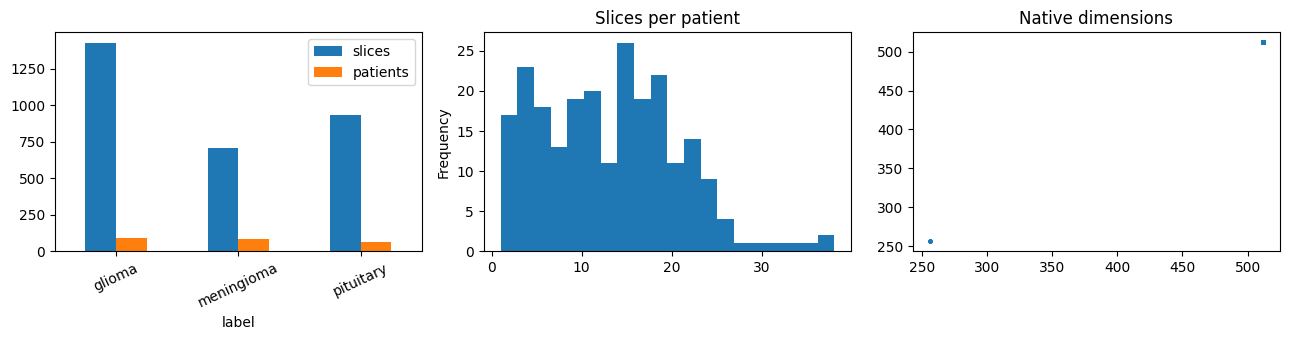

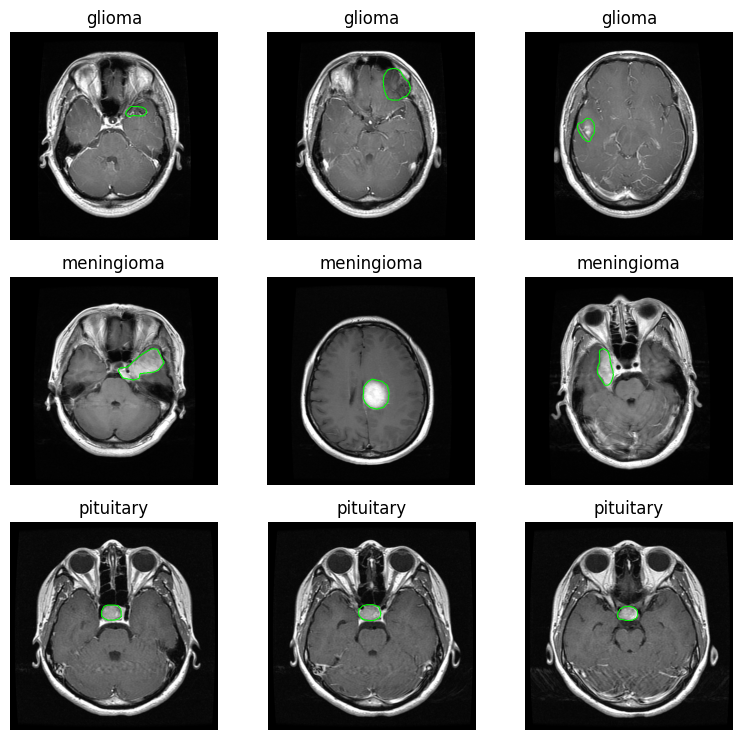

Cross-patient duplicate audit:   0%|          | 0/3064 [00:00<?, ?it/s]

Per-image normalization:   0%|          | 0/3064 [00:00<?, ?it/s]

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 221MB/s]


Patients: 233 | slices: 3064 | outer/inner: 5 3
fold 1/5 pixels32 seed 13 Amplitude4: inner F1 0.741
fold 1/5 pixels32 seed 13 Passive5: inner F1 0.690
fold 1/5 pixels32 seed 13 Coherent5: inner F1 0.642
fold 1/5 pixels32 seed 13 QuadraticLift_LR: inner F1 0.703
fold 1/5 pixels32 seed 13 QuadraticDirection_LR: inner F1 0.701
fold 1/5 pixels32 seed 13 PCA_LR: inner F1 0.693
fold 1/5 pixels32 seed 13 PCA_SVM: inner F1 0.769
fold 1/5 pixels32 seed 13 PCA_RF: inner F1 0.717
fold 1/5 pixels32 seed 29 Amplitude4: inner F1 0.691
fold 1/5 pixels32 seed 29 Passive5: inner F1 0.649
fold 1/5 pixels32 seed 29 Coherent5: inner F1 0.640
fold 1/5 pixels32 seed 29 QuadraticLift_LR: inner F1 0.703
fold 1/5 pixels32 seed 29 QuadraticDirection_LR: inner F1 0.701
fold 1/5 pixels32 seed 29 PCA_LR: inner F1 0.693
fold 1/5 pixels32 seed 29 PCA_SVM: inner F1 0.769
fold 1/5 pixels32 seed 29 PCA_RF: inner F1 0.729
fold 1/5 pixels32 seed 47 Amplitude4: inner F1 0.688
fold 1/5 pixels32 seed 47 Passive5: inner F1 

Verify Task 4 native data checksums:   0%|          | 0/3064 [00:00<?, ?it/s]

,slices,patients
label,,
glioma,1426,89
meningioma,708,82
pituitary,930,62


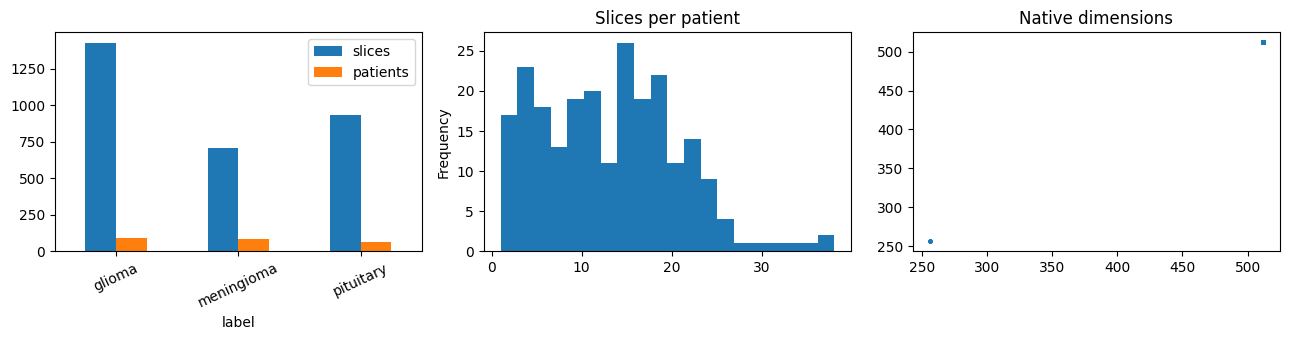

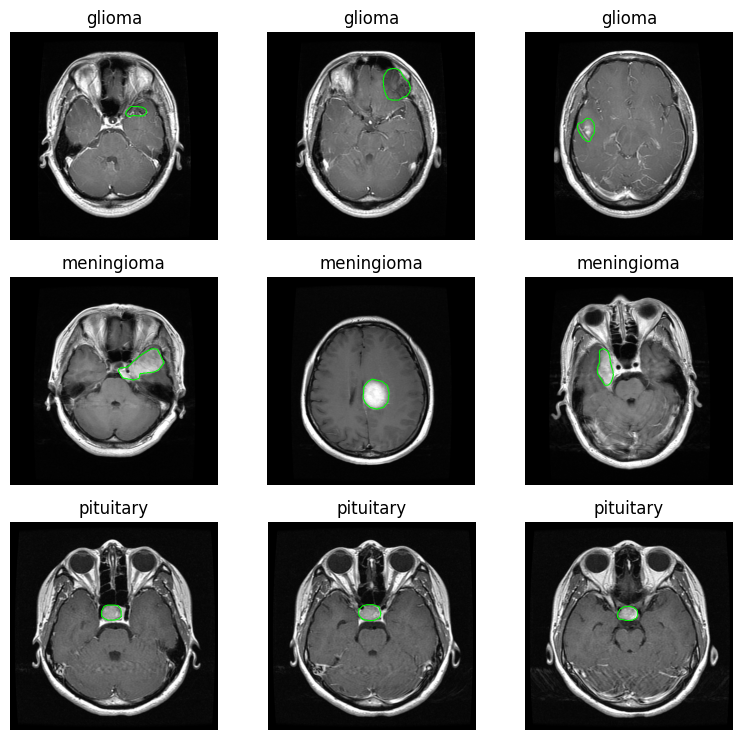

Reusing exact Task 4 folds and models. Historical subset: 45 patients.


In [18]:
TASK4_DIR, TASK4_COMPLETION, TASK4_PROTOCOL, PLANS, FRAME, LEGACY, TASK4_FEATURE_IDENTITY = load_task4_run()
CFG = copy.deepcopy(TASK4_PROTOCOL['cfg'])
VIEWS = TASK4_PROTOCOL['views']; SPLIT_SEED = TASK4_PROTOCOL['split_seed']
LEGACY_IDS = set(LEGACY['patient_ids'])
# Check every required checkpoint before downloading data or starting occlusion.
for view in VIEWS:
    for plan in PLANS:
        bundle_path = TASK4_DIR/view/f'fold_{plan["fold"]:02d}'/'bundle.joblib'
        if not bundle_path.is_file():
            raise FileNotFoundError(f'Missing trained Task 4 model: {bundle_path}. Restore the full Task4 results ZIP.')
        bundle = joblib.load(bundle_path)
        if (bundle.get('protocol_sha256') != TASK4_COMPLETION['protocol_sha256']
                or bundle.get('view') != view or bundle.get('fold') != plan['fold']
                or set(bundle['test_patients']) != set(plan['test_patients'])
                or set(bundle['development_patients']) != set(plan['development_patients'])
                or set(bundle['models']) != set(CFG['seeds'])
                or not np.array_equal(bundle['test_indices'], idx_for(FRAME, plan['test_patients']))
                or set(bundle['fit_indices']) - set(idx_for(FRAME, plan['development_patients']))):
            raise ValueError(f'Task 4 model metadata or saved row indices do not match: {bundle_path}')
        for models in bundle['models'].values():
            required_models = {'Coherent5','Passive5','QuadraticLift_LR',bundle['selected_classical']}
            if not required_models.issubset(models):
                raise ValueError(f'Incomplete Task 4 trained models: {bundle_path}')
slice_path = TASK4_DIR/'slice_oof_predictions.csv'
if not slice_path.is_file():
    raise FileNotFoundError('Task 4 slice_oof_predictions.csv is missing. Restore the complete results ZIP.')
TASK4_SLICES = pd.read_csv(slice_path, dtype={'sample_id':str,'patient_id':str})
required = {'view','fold','seed','model','sample_id','patient_id','label_id',*[f'p{j}' for j in range(K)]}
if not required.issubset(TASK4_SLICES.columns):
    raise ValueError('Task 4 saved slice predictions have missing columns.')
if TASK4_SLICES.duplicated(['view','seed','model','sample_id']).any():
    raise ValueError('Task 4 saved slice predictions contain duplicate rows.')
for view in VIEWS:
    for plan in PLANS:
        part = FRAME.iloc[idx_for(FRAME, plan['test_patients'])].set_index('sample_id')
        for seed in CFG['seeds']:
            for model in ['Coherent5','Passive5','QuadraticLift_LR','SelectedClassical']:
                saved = TASK4_SLICES[(TASK4_SLICES.view==view)&(TASK4_SLICES.fold==plan['fold'])&
                                    (TASK4_SLICES.seed==seed)&(TASK4_SLICES.model==model)].set_index('sample_id')
                if set(saved.index) != set(part.index):
                    raise ValueError(f'Incomplete Task 4 slice predictions: {view}, fold {plan["fold"]}, seed {seed}, {model}')
                saved = saved.loc[part.index]
                if not (np.array_equal(saved.patient_id,part.patient_id) and np.array_equal(saved.label_id,part.label_id)):
                    raise ValueError('Saved Task 4 slice prediction identities differ from the manifest.')
                pp = pcols(saved)
                if not np.isfinite(pp).all() or (pp<0).any() or not np.allclose(pp.sum(1),1,atol=1e-6):
                    raise ValueError('Invalid saved Task 4 slice probabilities.')
FRAME = reconnect_task4_data(FRAME)
FRAME.to_csv(OUT/'manifest.csv', index=False); dataset_eda(FRAME)
print('Reusing exact Task 4 folds and models. Historical subset:', len(LEGACY_IDS), 'patients.')
PROTOCOL = dict(task=2, profile=PROFILE, engine_signature=ENGINE_SIGNATURE,
    task4_protocol=TASK4_COMPLETION['protocol_sha256'], all_slices=True,
    mask_intervention='after fixed clean normalization before resize',
    translation='no wrapping or clipping; equal area; zero tumor overlap; image-only placement', bootstrap=CFG['bootstrap'])
p = OUT/'protocol.json'
if p.exists() and json.loads(p.read_text()) != PROTOCOL:
    raise ValueError('Existing Task 2 output uses a different protocol or Task 4 run. Change RUN_NAME.')
write_json(p, PROTOCOL)


## Native mask checks and displaced control masks

In [19]:
from scipy.signal import fftconvolve
from scipy.ndimage import label as connected_components, binary_closing

def displaced_control(clean,mask):
    if mask.shape!=clean.shape or not mask.any() or mask.all():raise ValueError('Empty/full/unaligned tumor mask')
    # A true translation: no np.roll wrapping, no clipping or changing the masked area.
    yy,xx=np.where(mask);y0,x0=yy.min(),xx.min();crop=mask[yy.min():yy.max()+1,xx.min():xx.max()+1]
    foreground=clean>.05
    labels,n=connected_components(foreground)
    if n:
        counts=np.bincount(labels.ravel());counts[0]=0;foreground=labels==counts.argmax()
    foreground=binary_fill_holes(binary_closing(foreground,iterations=2))
    area=int(mask.sum());kernel=crop[::-1,::-1].astype(float)
    overlap=fftconvolve(mask.astype(float),kernel,mode='valid')
    tissue=fftconvolve(foreground.astype(float),kernel,mode='valid')/area
    mean_signal=fftconvolve(clean.astype(float),kernel,mode='valid')/area
    py,px=np.indices(overlap.shape);distance=np.sqrt((py-y0)**2+(px-x0)**2)
    valid=(overlap<.5)&(distance>=max(2.,.5*math.sqrt(area/np.pi)))
    if not valid.any():raise ValueError('No nonoverlapping, area-preserving displaced mask fits. This image is explicitly unresolved; no replacement or silent exclusion.')
    # Choose tissue coverage first, then similar mean intensity, then shorter displacement.
    # All choices are image/mask based and fixed before looking at model predictions.
    max_tissue=float(tissue[valid].max());candidates=valid&(tissue>=max_tissue-.005)
    desired=float(clean[mask].mean());cost=abs(mean_signal-desired)+1e-5*distance
    cost[~candidates]=np.inf;top,left=np.unravel_index(np.argmin(cost),cost.shape)
    out=np.zeros_like(mask);out[top:top+crop.shape[0],left:left+crop.shape[1]]=crop
    assert out.sum()==mask.sum() and not np.logical_and(out,mask).any()
    return out,dict(displacement_y=int(top-y0),displacement_x=int(left-x0),control_foreground_fraction=float(foreground[out].mean()),
        tumor_foreground_fraction=float(foreground[mask].mean()),control_area=int(out.sum()),tumor_area=area,
        tumor_control_intersection=int(np.logical_and(out,mask).sum()),control_low_tissue_coverage=bool(foreground[out].mean()<.90))

def occlusion_variants(row):
    raw,mask,pid,label,fields=read_mat(row.path)
    if mask is None or not mask.any():raise ValueError('Missing/empty tumorMask: '+row.path)
    assert pid==row.patient_id and label==row.label
    clean=normalize_image(raw);control,qc=displaced_control(clean,mask)
    outside=(clean>.05)&~mask&~control
    fill=float(np.median(clean[outside])) if outside.any() else float(np.median(clean))
    tumor=clean.copy();displaced=clean.copy();tumor[mask]=fill;displaced[control]=fill
    assert np.array_equal(tumor[~mask],clean[~mask]) and np.array_equal(displaced[~control],clean[~control])
    qc.update(sample_id=row.sample_id,patient_id=pid,label_id=int(row.label_id),mask_field_present='tumorMask' in fields,
        native_height=raw.shape[0],native_width=raw.shape[1],fill_value=fill,tumor_fraction=float(mask.mean()),
        original_45=pid in LEGACY_IDS)
    return clean,tumor,displaced,mask,control,qc


## Run all slices using their saved outer-fold models

In [20]:
def run_full_occlusion():
    rows=[];qc_rows=[];plot_count=0
    for view in VIEWS:
        for plan in PLANS:
            fold=plan['fold'];bundle_path=TASK4_DIR/view/f'fold_{fold:02d}'/'bundle.joblib'
            if not bundle_path.exists():raise FileNotFoundError('Complete Task 4 first: '+str(bundle_path))
            bundle=joblib.load(bundle_path);assert bundle['protocol_sha256']==TASK4_COMPLETION['protocol_sha256']
            assert set(bundle['test_patients'])==set(plan['test_patients'])
            assert not set(bundle['development_patients'])&set(plan['test_patients'])
            ii=idx_for(FRAME,plan['test_patients']);part=FRAME.iloc[ii]
            cp=OUT/f'occlusion_{view}_fold_{fold:02d}.joblib'
            cache_id=digest(dict(task4=bundle['identity'],mask_version='native_fixed_normalization_displaced_v1',scope='all_outer_test_slices',seeds=CFG['seeds']))
            if cp.exists():
                cached=joblib.load(cp);assert cached['identity']==cache_id
                rows.extend(cached['rows']);qc_rows.extend(cached['qc']);continue
            clean=[];tumor=[];control=[];local_qc=[]
            for r in tqdm(part.itertuples(),total=len(part),desc=f'{view} fold{fold} native occlusion'):
                a,b,c,m,cm,qc=occlusion_variants(r);clean.append(a);tumor.append(b);control.append(c);local_qc.append(qc)
                if view==VIEWS[0] and plot_count<3:
                    fig,axs=plt.subplots(1,4,figsize=(10,3))
                    for ax,im,title in zip(axs,[a,b,c,a],['Clean','Tumor occluded','Displaced control','Native masks']):ax.imshow(im,cmap='gray',vmin=0,vmax=1);ax.set_title(title);ax.axis('off')
                    axs[3].contour(m,levels=[.5],colors=['red']);axs[3].contour(cm,levels=[.5],colors=['cyan'])
                    savefig(fig,f'mask_example_{plot_count}');plot_count+=1
            if view=='pixels32':
                raw_sets=[np.stack([resize_float(x,32).ravel() for x in ims]).astype(float) for ims in [clean,tumor,control]]
            elif PROFILE=='smoke':
                projection=np.random.default_rng(411).normal(size=(1024,64))/np.sqrt(1024)
                raw_sets=[np.stack([resize_float(x,32).ravel() for x in ims])@projection for ims in [clean,tumor,control]]
            else:raw_sets=[resnet_features(ims).astype(float) for ims in [clean,tumor,control]]
            prepared=[prep_transform(bundle['prep'],x) for x in raw_sets];local=[]
            chosen=['Coherent5','Passive5','QuadraticLift_LR','SelectedClassical']
            for seed in CFG['seeds']:
                for name in chosen:
                    actual=bundle['selected_classical'] if name=='SelectedClassical' else name
                    model=bundle['models'][seed][actual];ps=[softmax(predict_record(model,d),axis=1) for d in prepared]
                    # The clean path must reproduce Task 4; otherwise the intervention would compare different pipelines.
                    reference=TASK4_SLICES[(TASK4_SLICES.view==view)&(TASK4_SLICES.fold==fold)&(TASK4_SLICES.seed==seed)&(TASK4_SLICES.model==name)].set_index('sample_id')
                    expected=reference.loc[part.sample_id,[f'p{j}' for j in range(K)]].to_numpy(float)
                    err=float(np.max(abs(ps[0]-expected)))
                    assert err<(1e-4 if view=='resnet18' else 1e-8), f'Clean-pipeline mismatch {view}/{name}: {err}'
                    for n,r in enumerate(part.itertuples()):
                        y=int(r.label_id);a,b,c=[p[n] for p in ps]
                        record=dict(view=view,fold=fold,seed=seed,model=name,selected_family=actual,sample_id=r.sample_id,patient_id=r.patient_id,label_id=y,
                            original_45=r.patient_id in LEGACY_IDS,clean_true_probability=float(a[y]),tumor_true_probability=float(b[y]),control_true_probability=float(c[y]),
                            tumor_probability_drop=float(a[y]-b[y]),control_probability_drop=float(a[y]-c[y]),
                            tumor_minus_control_drop=float(c[y]-b[y]),clean_reproduction_max_error=err)
                        for condition,p in zip(['clean','tumor','control'],[a,b,c]):
                            record.update({condition+f'_p{j}':float(p[j]) for j in range(K)})
                        local.append(record)
            for q in local_qc:q['view']=view
            atomic_joblib(dict(identity=cache_id,rows=local,qc=local_qc),cp)
            rows.extend(local);qc_rows.extend(local_qc)
    return pd.DataFrame(rows),pd.DataFrame(qc_rows)


## Patient-cluster bootstrap with all models and seeds paired

In [21]:
def occlusion_summary(table,frame):
    effects=[];metrics_rows=[]
    group_map=frame[['patient_id','split_group']].drop_duplicates().set_index('patient_id').split_group
    for scope,source in [('all_233_oof',table),('historical_45_oof_subset',table[table.original_45])]:
        for (view,model),sub in source.groupby(['view','model']):
            if sub.empty:continue
            patient=sub.groupby(['seed','patient_id','label_id'],as_index=False)[['tumor_probability_drop','control_probability_drop','tumor_minus_control_drop']].mean()
            ids=sorted(patient.patient_id.unique());seeds=CFG['seeds'];ys=patient.drop_duplicates('patient_id').set_index('patient_id').loc[ids].label_id.to_numpy(int)
            linked=group_map.loc[ids].to_numpy();ug=np.unique(linked);rng=np.random.default_rng(818)
            arrays={key:np.stack([patient[patient.seed==s].set_index('patient_id').loc[ids,key].to_numpy(float) for s in seeds]) for key in ['tumor_probability_drop','control_probability_drop','tumor_minus_control_drop']}
            draws={k:[] for k in arrays}
            for _ in range(CFG['bootstrap']):
                if len(ug)<len(ids):
                    sampled=rng.choice(ug,len(ug),replace=True);ii=np.concatenate([np.flatnonzero(linked==g) for g in sampled])
                else:ii=stratified_resample(ys,rng)
                ss=rng.integers(0,len(seeds),len(seeds))
                for key,a in arrays.items():draws[key].append(float(a[np.ix_(ss,ii)].mean()))
            for key,a in arrays.items():
                lo,hi=np.quantile(draws[key],[.025,.975])
                effects.append(dict(scope=scope,view=view,model=model,effect=key,estimate=float(a.mean()),ci_low=float(lo),ci_high=float(hi),
                    n_patients=len(ids),n_slices=sub.sample_id.nunique(),n_seeds=len(seeds),
                    interval_scope='patient (or linked-patient cluster) and seed bootstrap; patients equally weighted; conditional on fitted outer folds'))
            # Secondary patient-level classification changes, paired with the probability analysis.
            patient_ps={}
            for condition in ['clean','tumor','control']:
                cols=[condition+f'_p{j}' for j in range(K)]
                grouped=sub.groupby(['seed','patient_id','label_id'])[cols].mean().reset_index()
                pp=np.stack([grouped[grouped.seed==s].set_index('patient_id').loc[ids,cols].to_numpy() for s in seeds]);patient_ps[condition]=pp
                metrics_rows.append(dict(scope=scope,view=view,model=model,condition=condition,mean_macro_f1=np.mean([metric(ys,p)['macro_f1'] for p in pp]),
                    mean_accuracy=np.mean([metric(ys,p)['accuracy'] for p in pp]),n_patients=len(ids)))
            delta=seed_patient_interval(ys,patient_ps['control'],patient_ps['tumor'],n_boot=CFG['bootstrap'],groups=linked if len(ug)<len(ids) else None)
            effects.append(dict(scope=scope,view=view,model=model,effect='control_minus_tumor_macro_f1',n_slices=sub.sample_id.nunique(),**delta))
    return pd.DataFrame(effects),pd.DataFrame(metrics_rows)


## Execute and reconcile complete coverage

pixels32 fold0 native occlusion:   0%|          | 0/596 [00:00<?, ?it/s]

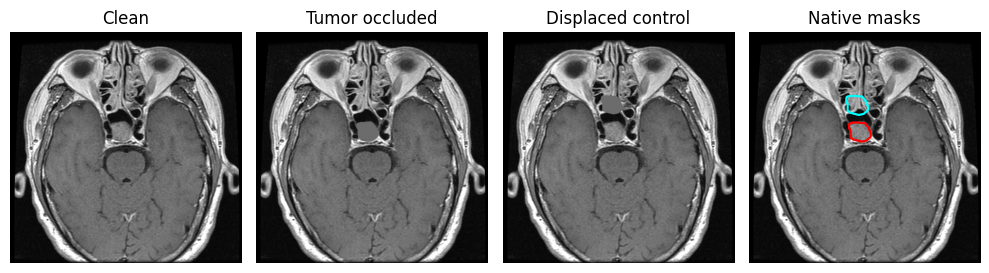

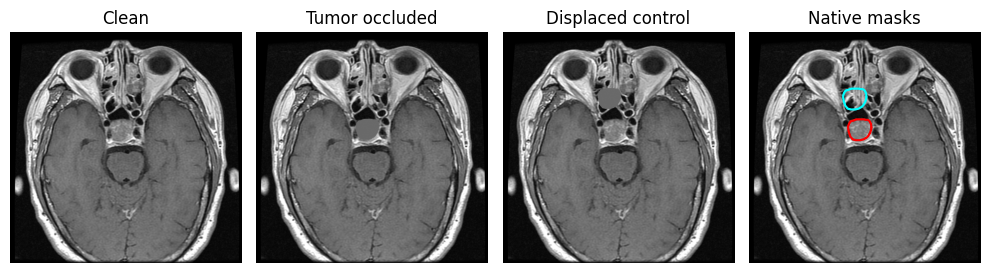

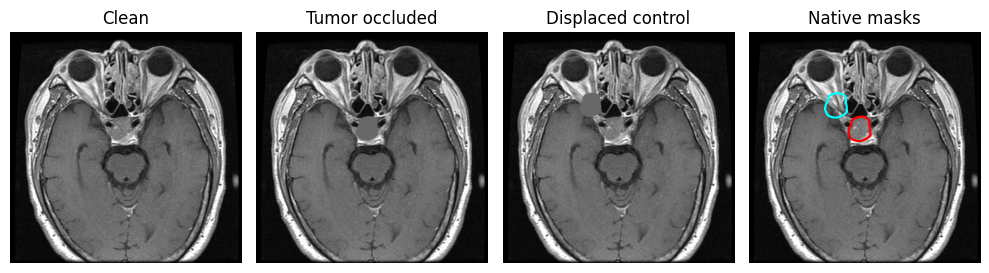

pixels32 fold1 native occlusion:   0%|          | 0/635 [00:00<?, ?it/s]

pixels32 fold2 native occlusion:   0%|          | 0/638 [00:00<?, ?it/s]

pixels32 fold3 native occlusion:   0%|          | 0/575 [00:00<?, ?it/s]

pixels32 fold4 native occlusion:   0%|          | 0/620 [00:00<?, ?it/s]

resnet18 fold0 native occlusion:   0%|          | 0/596 [00:00<?, ?it/s]

resnet18 fold1 native occlusion:   0%|          | 0/635 [00:00<?, ?it/s]

resnet18 fold2 native occlusion:   0%|          | 0/638 [00:00<?, ?it/s]

resnet18 fold3 native occlusion:   0%|          | 0/575 [00:00<?, ?it/s]

resnet18 fold4 native occlusion:   0%|          | 0/620 [00:00<?, ?it/s]

,scope,view,model,effect,estimate,ci_low,ci_high,n_patients,n_slices,n_seeds,interval_scope,patient_only_low,patient_only_high,n_boot
0,all_233_oof,pixels32,Coherent5,tumor_probability_drop,0.00001,-0.00036,0.00039,233,3064,5,patient (or linked-patient cluster) and seed b...,NaN,NaN,NaN
1,all_233_oof,pixels32,Coherent5,control_probability_drop,0.00051,-0.00003,0.00100,233,3064,5,patient (or linked-patient cluster) and seed b...,NaN,NaN,NaN
2,all_233_oof,pixels32,Coherent5,tumor_minus_control_drop,-0.00049,-0.00098,0.00001,233,3064,5,patient (or linked-patient cluster) and seed b...,NaN,NaN,NaN
3,all_233_oof,pixels32,Coherent5,control_minus_tumor_macro_f1,-0.00187,-0.01981,0.01674,233,3064,5,paired seed and patient/linked-cluster resampl...,-0.01234,0.00847,3000.0
4,all_233_oof,pixels32,Passive5,tumor_probability_drop,-0.00016,-0.00048,0.00017,233,3064,5,patient (or linked-patient cluster) and seed b...,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,historical_45_oof_subset,resnet18,QuadraticLift_LR,control_minus_tumor_macro_f1,0.01954,-0.06477,0.10705,45,591,5,paired seed and patient/linked-cluster resampl...,-0.06477,0.10705,3000.0
60,historical_45_oof_subset,resnet18,SelectedClassical,tumor_probability_drop,0.04654,0.02177,0.07759,45,591,5,patient (or linked-patient cluster) and seed b...,NaN,NaN,NaN
61,historical_45_oof_subset,resnet18,SelectedClassical,control_probability_drop,0.00467,-0.02274,0.02650,45,591,5,patient (or linked-patient cluster) and seed b...,NaN,NaN,NaN
62,historical_45_oof_subset,resnet18,SelectedClassical,tumor_minus_control_drop,0.04187,0.00427,0.09271,45,591,5,patient (or linked-patient cluster) and seed b...,NaN,NaN,NaN


,scope,view,model,condition,mean_macro_f1,mean_accuracy,n_patients
0,all_233_oof,pixels32,Coherent5,clean,0.5679,0.5888,233
1,all_233_oof,pixels32,Coherent5,tumor,0.5643,0.5863,233
2,all_233_oof,pixels32,Coherent5,control,0.5624,0.5854,233
3,all_233_oof,pixels32,Passive5,clean,0.6138,0.6215,233
4,all_233_oof,pixels32,Passive5,tumor,0.6222,0.6275,233
5,all_233_oof,pixels32,Passive5,control,0.6143,0.6206,233
6,all_233_oof,pixels32,QuadraticLift_LR,clean,0.7414,0.7296,233
7,all_233_oof,pixels32,QuadraticLift_LR,tumor,0.7454,0.7339,233
8,all_233_oof,pixels32,QuadraticLift_LR,control,0.7206,0.7082,233
9,all_233_oof,pixels32,SelectedClassical,clean,0.7592,0.7425,233


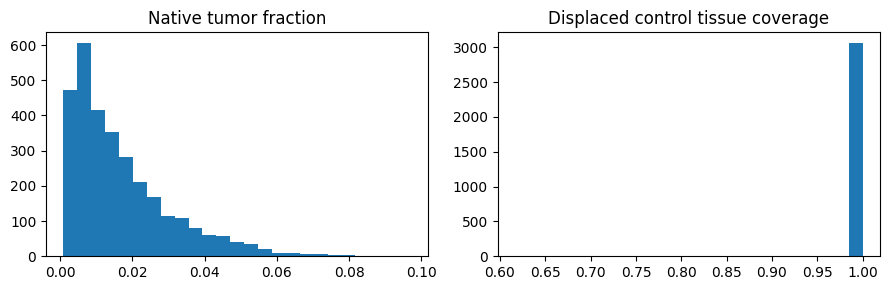

In [22]:
OCCLUSION,MASK_QC=run_full_occlusion()
assert not OCCLUSION.duplicated(['view','seed','model','sample_id']).any()
for (view,seed,model),s in OCCLUSION.groupby(['view','seed','model']):
    assert set(s.sample_id)==set(FRAME.sample_id)
    assert set(s[s.original_45].sample_id)==set(FRAME.loc[FRAME.patient_id.isin(LEGACY_IDS),'sample_id'])
assert MASK_QC.mask_field_present.all() and (MASK_QC.control_area==MASK_QC.tumor_area).all()
assert (MASK_QC.tumor_control_intersection==0).all()
OCCLUSION.to_csv(OUT/'all_slice_occlusion_predictions.csv',index=False);MASK_QC.to_csv(OUT/'native_mask_control_quality.csv',index=False)
EFFECTS,OCC_METRICS=occlusion_summary(OCCLUSION,FRAME)
# A transparent secondary sensitivity analysis; the all-slice primary result above remains complete.
quality=MASK_QC[['view','sample_id','control_foreground_fraction']].drop_duplicates()
quality_join=OCCLUSION.merge(quality,on=['view','sample_id'],validate='many_to_one')
good=quality_join[quality_join.control_foreground_fraction>=.90]
if len(good) and good.patient_id.nunique()>=3:
    sensitivity,sensitivity_metrics=occlusion_summary(good,FRAME)
    sensitivity.to_csv(OUT/'secondary_tissue_coverage_ge_090_effects.csv',index=False)
    sensitivity_metrics.to_csv(OUT/'secondary_tissue_coverage_ge_090_metrics.csv',index=False)
EFFECTS.to_csv(OUT/'patient_paired_occlusion_intervals.csv',index=False);OCC_METRICS.to_csv(OUT/'patient_occlusion_metrics.csv',index=False)
display(EFFECTS.round(5));display(OCC_METRICS.round(4))
fig,axes=plt.subplots(1,2,figsize=(9,3))
first=MASK_QC[MASK_QC.view==VIEWS[0]]
axes[0].hist(first.tumor_fraction,bins=25);axes[0].set_title('Native tumor fraction')
axes[1].hist(first.control_foreground_fraction,bins=25);axes[1].set_title('Displaced control tissue coverage')
savefig(fig,'mask_area_and_control_coverage_eda')


## Figures and cautious result wording for the paper

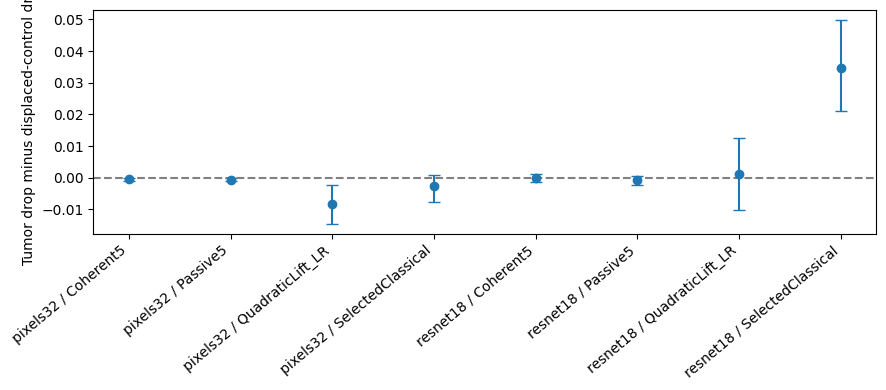

Results bundle: /content/Brain_MRI_Faculty_Revision/task2/Task2_paper_v1.zip


In [23]:
s=EFFECTS[(EFFECTS.scope=='all_233_oof')&(EFFECTS.effect=='tumor_minus_control_drop')]
fig,ax=plt.subplots(figsize=(9,4));xx=np.arange(len(s));ax.errorbar(xx,s.estimate,yerr=[np.maximum(0,s.estimate-s.ci_low),np.maximum(0,s.ci_high-s.estimate)],fmt='o',capsize=4)
ax.axhline(0,color='gray',ls='--');ax.set_xticks(xx,s.view+' / '+s.model,rotation=40,ha='right');ax.set_ylabel('Tumor drop minus displaced-control drop');savefig(fig,'occlusion_patient_effects')
lines=['# Task 2 results','', 'Our design choices were informed by data that included the test patients.', '',
'Native cjdata.tumorMask fields, orientation, binary values and nonempty masks were checked on every slice. All slices of all outer test patients were processed. The historical 45-patient subset is reported separately, using out-of-fold models; it is not treated as a fresh independent holdout.', '',
'Each displaced control is a nonwrapping translation of the native tumor mask with exactly equal pixel area and zero tumor overlap. Selection uses only the image and the mask, never model predictions. The tumor and control share a fill value. Tissue-coverage quality is exported for every image; large lesions may force displaced controls partly outside the brain.', '',
'Occlusion is applied after the clean image normalization has been fixed, before resizing/features. Thus only masked normalized pixels change; percentile re-estimation cannot introduce an unmasked global-intensity change. Fitted models, PCA, norm scaling, classical family selection and all other training quantities remain frozen.', '',
'A secondary sensitivity table restricts slices to displaced-control tissue coverage of at least 90 percent. Its retained sample sizes are explicit; primary results keep every slice.', '',
'Scores use the Task 4 softmax decision rules at temperature 1. They have not been independently probability-calibrated; SVM softmax margins in particular are normalized decision scores. Comparisons are paired within each model.', '',
'Probability drops are first averaged over slices within each patient. Paired intervals resample complete patients or linked-patient clusters and whole seeds. Positive tumor-minus-control drops indicate more sensitivity to the tumor region than to the displaced control. A near-zero effect with a wide interval is inconclusive; it does not prove that a model ignores tumors.', '',
EFFECTS.to_markdown(index=False), '',
'Abstract revision guidance: If full-mask results show little additional tumor sensitivity with sufficiently narrow intervals, report that finding plainly in the Abstract. If intervals remain wide, state that tumor reliance was unresolved. Occlusion alone cannot establish a causal anatomical mechanism.', '',
'Legacy subset membership: '+LEGACY['membership_status']]
if PROFILE=='smoke':lines.insert(1,'SYNTHETIC ENGINEERING CHECK — not MRI results.')
(OUT/'TASK2_RESULTS.md').write_text('\n'.join(lines))
write_json(OUT/'completion.json',dict(task=2,profile=PROFILE,task4_protocol=TASK4_COMPLETION['protocol_sha256'],n_patients=FRAME.patient_id.nunique(),
    n_slices=len(FRAME),historical_subset_patients=len(LEGACY_IDS),historical_subset_slices=int(FRAME.patient_id.isin(LEGACY_IDS).sum()),
    complete_all_slice_coverage=True,mask_field_confirmed_for_every_slice=True,
    low_tissue_control_slices=int(MASK_QC[MASK_QC.view==VIEWS[0]].control_low_tissue_coverage.sum())))
PACKAGE=package_outputs(OUT,'Task2_'+OUT.name)


## Outputs and reruns

All tables, plots, predictions, protocol records and model checkpoints are in the printed output directory. A ZIP is created at the end. Completed candidate/fold checkpoints are reused only with matching identities. In Colab, keep Google Drive enabled to continue after a runtime reset. Do not publish smoke-mode values.

Sources checked for this implementation: [native Figshare dataset](https://figshare.com/articles/dataset/brain_tumor_dataset/1512427), [nested CV documentation](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html), [ViT weights](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.vit_b_16.html), [Swin weights](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.swin_t.html). Model definitions and historical numbers are traced to the supplied paper and notebooks.